# Environmental sound classification with AST
**Final project · CISC 473 · CPU notebook**

Start here even with no previous downloads or results. Use a Python 3.11 or 3.12 Jupyter kernel. Run section 1 once per environment; restart the kernel after installing, then run from section 2 down. Leave the switches at their defaults for the recommended report. Every expensive stage writes to the printed project folder. Keep that folder, not just the notebook, to resume later. A fresh run populates the plots inline and saves the same figures on disk.

The primary experiment is the three-seed, five-fold ESC-50 comparison of CPCP against three baselines. The secondary experiments use lighter, declared budgets. Their scores answer different questions: do not pool the small-budget fine-tuning results, the frozen-feature results or the single-fold patch study. The 94% goal is a target, not a result.

**Three-seed edition:** starts in a new project folder, cisc473_audio_three_seeds. All required quantitative comparisons use seeds 42, 123 and 999. Section 14 validates coverage before issuing the final ZIP. The patch comparison is still a matched fold-1 experiment.


## 1 · Install once
Use a dedicated VS Code notebook kernel. These pins install torch, torchaudio and torchvision together in **this kernel**, including the matching torchvision build needed by the Transformers imports. Restart the kernel after this cell. On future sessions in the same environment start at section 2.


In [1]:
import sys, subprocess
packages=['torch==2.6.0','torchvision==0.21.0','torchaudio==2.6.0']
command=[sys.executable,'-m','pip','install',*packages]
if sys.platform.startswith('linux'):command+=['--index-url','https://download.pytorch.org/whl/cpu']
subprocess.check_call(command)
subprocess.check_call([sys.executable,'-m','pip','install','transformers==4.48.3','huggingface-hub==0.28.1','safetensors==0.5.3','soundfile==0.13.1','numpy>=1.26,<3','scipy>=1.11,<2','pandas>=2.2,<3','scikit-learn>=1.4,<2','matplotlib>=3.8,<4','tqdm>=4.66,<5','psutil'])

print('Installation finished. Restart this notebook kernel, then run section 2 onward.')



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python3.11 -m pip install --upgrade pip


Installation finished. Restart this notebook kernel, then run section 2 onward.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python3.11 -m pip install --upgrade pip


## 2 · Configuration
No smoke run or previous results required. `MODE='pilot'` is the inherited data-loader name for retaining all eligible ESC-50 classes and clips. The final cells below explicitly iterate over the official folds. Keep the project folder in a permanent location with space for the Urban archive, extracted audio, weights and caches. The transfer can be interrupted and resumed. Budget changes get their own results folder.


In [2]:
import sys, subprocess, importlib.metadata as package_metadata
from pathlib import Path
import os, json, hashlib, time, random, math, shutil, copy, platform
from urllib.request import Request, urlopen
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import scipy
from scipy import signal
import soundfile as sf
import matplotlib.pyplot as plt
expected={'torch':'2.6.0','torchvision':'0.21.0','torchaudio':'2.6.0','transformers':'4.48.3'}
for pkg,want in expected.items():
    try:have=package_metadata.version(pkg).split('+')[0]
    except package_metadata.PackageNotFoundError:have='missing'
    if have!=want:raise RuntimeError(f'{pkg}: found {have}, need {want}. Run section 1 in this kernel, restart it, then begin at section 2.')
import torch
import torchaudio
from torch import nn
from transformers import ASTForAudioClassification
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm
from IPython.display import display, Audio

MODE = "pilot"                        # Full eligible ESC-50 data for the final experiments.
SEEDS = [42, 123, 999]
TEST_FOLD, VAL_FOLD = 4, 5            # Train on official folds 1, 2, 3.
SMOKE_CLASS_IDS = [0, 1, 2, 3, 4]    # dog, rooster, pig, cow, frog
SMOKE_PER_CLASS_PER_FOLD = 2
SAMPLE_RATE, MEL_BINS, FRAMES = 16000, 128, 512
WAVEFORM_GAIN = 0.1                 # Common headroom for clean and filtered audio.
MODEL_ID = "MIT/ast-finetuned-audioset-10-10-0.4593"
MODEL_REV = "f826b80d28226b62986cc218e5cec390b1096902"
ESC_REV = "33c8ce9eb2cf0b1c2f8bcf322eb349b6be34dbb6"
PIPELINE_VERSION = "cisc473-cpcp-v1"
ROOT = Path(os.environ.get("CISC473_THREE_SEED_ROOT","cisc473_audio_three_seeds")).expanduser().resolve()
DATA_DIR, MODEL_DIR, CACHE_DIR = ROOT/"data", ROOT/"models"/"ast", ROOT/"feature_cache"
EXTRACTION_THREADS = min(4, os.cpu_count() or 1)
DEVICE = torch.device("cpu")
MAX_EPOCHS = 30 if MODE == "smoke" else 25
PATIENCE = 6 if MODE == "smoke" else 5
L2_GRID = [1e-4, 1e-3] if MODE == "smoke" else [1e-4, 1e-3]
RANK_GRID = [0, 2, 4] if MODE == "smoke" else [0, 16, 64]
LR, HEAD_BATCH = 1e-3, 64
CLEAN_TOLERANCE = 0.01               # Absolute accuracy fraction = 1 percentage point.
assert MODE in {"smoke", "pilot"}
assert TEST_FOLD != VAL_FOLD and {TEST_FOLD, VAL_FOLD} <= set(range(1,6))
for folder in [DATA_DIR, MODEL_DIR, CACHE_DIR]: folder.mkdir(parents=True, exist_ok=True)

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""): h.update(chunk)
    return h.hexdigest()

def save_json(path, obj):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")

run_config = dict(mode=MODE, seeds=SEEDS, test_fold=TEST_FOLD, val_fold=VAL_FOLD,
    smoke_classes=SMOKE_CLASS_IDS, smoke_per_fold=SMOKE_PER_CLASS_PER_FOLD,
    model=MODEL_ID, model_revision=MODEL_REV, dataset_revision=ESC_REV,source_policy="exclude_all_cross_fold_source_ids",
    sample_rate=SAMPLE_RATE, mel_bins=MEL_BINS, frames=FRAMES, waveform_gain=WAVEFORM_GAIN,
    max_epochs=MAX_EPOCHS, patience=PATIENCE, learning_rate=LR, batch_size=HEAD_BATCH,
    l2_grid=L2_GRID, rank_grid=RANK_GRID, clean_tolerance=CLEAN_TOLERANCE,
    pipeline_version=PIPELINE_VERSION, device=str(DEVICE))
RUN_DIR = ROOT/"runs"/(MODE + "_" + digest(run_config)[:10])
RUN_DIR.mkdir(parents=True, exist_ok=True)
save_json(RUN_DIR/"configuration.json", run_config)
runtime = {p: package_metadata.version(p) for p in
           ["torch", "torchaudio", "transformers", "numpy", "scipy", "pandas", "scikit-learn", "soundfile"]}
runtime.update(python=sys.version, platform=platform.platform(), threads=EXTRACTION_THREADS)
save_json(RUN_DIR/"runtime.json", runtime)
(RUN_DIR/"pip_freeze.txt").write_text(subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"], text=True))
torch.set_num_threads(EXTRACTION_THREADS)
torch.use_deterministic_algorithms(True)
print("Mode:", MODE, "| run folder:", RUN_DIR)

# Recommended from-scratch run. No need to turn everything on.
RUN_ESC_CORE = RUN_URBAN_CORE = RUN_AUGMENTATION = RUN_CNN = True
RUN_FULL_AST = RUN_PATCH_ABLATION = RUN_TRANSFER = RUN_ATTENTION = True
RUN_BOOTSTRAP = RUN_EXPORT = DOWNLOAD_URBAN = True
RUN_SECONDARY = False  # Optional random, unpaired, class-mean projection controls
RUN_PANNS = False      # Optional second backbone; separate package and checkpoint
SAMPLE_SEED = 42  # Keep training clips fixed while model initialization varies.
assert len(SEEDS)==len(set(SEEDS))==3
HEAD_L2, HEAD_EPOCHS = .001, 20
AST_PER_CLASS, AST_EPOCHS = 4, 1  # Per outer training set; None uses every non-test clip
CNN_EPOCHS = 3
URBAN_ROOT=ROOT/'UrbanSound8K'
SPEC_DIR=ROOT/'spectrogram_cache';SPEC_DIR.mkdir(exist_ok=True)
assert MODE=='pilot', 'Final report runs require all eligible ESC classes (MODE="pilot").'
print('Keep this folder to resume:',ROOT)


/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Mode: pilot | run folder: /Users/masih/Downloads/cisc473_audio_three_seeds/runs/pilot_401c836377
Keep this folder to resume: /Users/masih/Downloads/cisc473_audio_three_seeds


## 3 ESC-50 data and pretrained AST
All 2,000 official metadata rows are audited. Nine clips with source IDs crossing official folds are excluded, matching the midterm protocol. The resulting 1,991-clip benchmark variant must be disclosed. Full CV rotates every retained official fold; test clips never select hyperparameters.

In [3]:
def download_file(url, destination):
    """Stream to a temporary file, then rename. A partial download is never reused."""
    destination = Path(destination)
    if destination.is_file() and destination.stat().st_size > 0: return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    partial = destination.with_name(destination.name + ".part")
    for attempt in range(3):
        try:
            req = Request(url, headers={"User-Agent": "CISC473-research-notebook/1.0"})
            with urlopen(req, timeout=120) as response, partial.open("wb") as out:
                shutil.copyfileobj(response, out, length=1024*1024)
                size=response.headers.get("Content-Length")
                if size and out.tell()!=int(size):raise IOError("Incomplete download: "+url)
            if partial.stat().st_size == 0: raise ValueError("Empty download")
            partial.replace(destination)
            return destination
        except Exception:
            partial.unlink(missing_ok=True)
            if attempt == 2: raise
            time.sleep(attempt + 1)

ESC_BASE = f"https://raw.githubusercontent.com/karolpiczak/ESC-50/{ESC_REV}"
META_PATH = download_file(ESC_BASE+"/meta/esc50.csv", DATA_DIR/ESC_REV/"esc50.csv")
all_meta = pd.read_csv(META_PATH)
assert len(all_meta) == 2000 and all_meta.target.nunique() == 50
assert all_meta.filename.is_unique
assert all_meta.groupby("fold").size().to_dict() == {i:400 for i in range(1,6)}
# Audit the official metadata, not just the selected subset.
source_fold_counts = all_meta.groupby("src_file").fold.nunique()
cross_fold_sources = source_fold_counts[source_fold_counts > 1].index
excluded = all_meta[all_meta.src_file.isin(cross_fold_sources)].copy()
excluded.to_csv(RUN_DIR/"excluded_cross_fold_sources.csv", index=False)
meta = all_meta[~all_meta.src_file.isin(cross_fold_sources)].copy()
assert meta.groupby("src_file").fold.nunique().max() == 1
print(f"Source audit: excluded {len(excluded)} clips from {len(cross_fold_sources)} cross-fold source IDs; {len(meta)} remain before smoke subsampling.")
if MODE == "smoke":
    meta = (meta[meta.target.isin(SMOKE_CLASS_IDS)].sort_values("filename")
            .groupby(["fold", "target"], group_keys=False).head(SMOKE_PER_CLASS_PER_FOLD))
meta = meta.sort_values("filename").reset_index(drop=True)
class_ids = sorted(meta.target.unique().tolist())
class_to_index = {int(original): i for i, original in enumerate(class_ids)}
class_names = [str(all_meta.loc[all_meta.target.eq(c), "category"].iloc[0]) for c in class_ids]
N_CLASSES = len(class_ids)
meta["label"] = meta.target.map(class_to_index)
meta["split"] = np.where(meta.fold.eq(TEST_FOLD), "test",
                          np.where(meta.fold.eq(VAL_FOLD), "val", "train"))
meta["path"] = meta.filename.map(lambda f: str(DATA_DIR/ESC_REV/"audio"/f))

def fetch_clip(row):
    return download_file(ESC_BASE+"/audio/"+row.filename, row.path)
with ThreadPoolExecutor(max_workers=4) as pool:
    list(tqdm(pool.map(fetch_clip, meta.itertuples()), total=len(meta), desc="Audio downloads"))

split_sources = {s:set(meta.loc[meta.split.eq(s), "src_file"]) for s in ["train","val","test"]}
assert not (split_sources["train"] & split_sources["val"])
assert not (split_sources["train"] & split_sources["test"])
assert not (split_sources["val"] & split_sources["test"])
assert meta.groupby(["split","label"]).size().size == 3*N_CLASSES
meta["audio_sha256"] = [file_sha256(p) for p in meta.path]
meta.to_csv(RUN_DIR/"selected_manifest.csv", index=False)
save_json(RUN_DIR/"classes.json", {"original_ids":class_ids, "names":class_names})
train_meta, val_meta, test_meta = [meta[meta.split.eq(s)].copy() for s in ["train","val","test"]]
display(meta.groupby("split").agg(clips=("filename","size"), classes=("label","nunique")))
print("Source separation check passed.")


Source audit: excluded 9 clips from 4 cross-fold source IDs; 1991 remain before smoke subsampling.


Audio downloads: 100%|██████████| 1991/1991 [02:14<00:00, 14.77it/s]


,clips,classes
split,,
test,398,50
train,1196,50
val,397,50


Source separation check passed.


Audio checks: 100%|██████████| 1991/1991 [00:03<00:00, 610.00it/s]


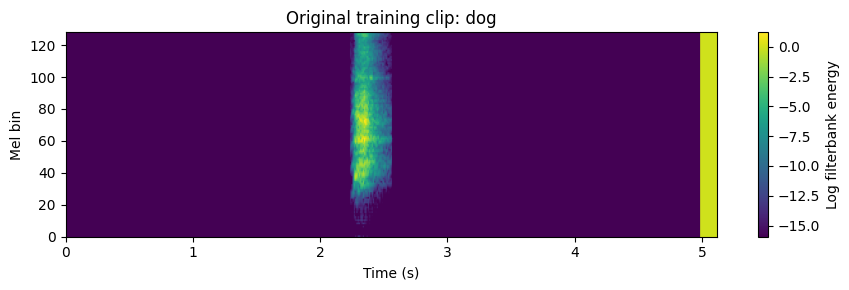

Input shape: (512, 128) | normalisation: -4.2677393 4.5689974


In [4]:
for name in ["config.json", "preprocessor_config.json"]:
    download_file(f"https://huggingface.co/{MODEL_ID}/resolve/{MODEL_REV}/{name}", MODEL_DIR/name)
preprocessor_config = json.loads((MODEL_DIR/"preprocessor_config.json").read_text())
NORM_MEAN = float(preprocessor_config["mean"])
NORM_STD = float(preprocessor_config["std"])
assert NORM_STD > 0

def load_audio(path):
    waveform, sr = sf.read(path, dtype="float32", always_2d=True)
    waveform = waveform.mean(axis=1)
    assert len(waveform) > 0 and np.isfinite(waveform).all()
    x = torch.from_numpy(waveform)
    if sr != SAMPLE_RATE: x = torchaudio.functional.resample(x, sr, SAMPLE_RATE)
    x = x - x.mean()
    return (x.numpy()*WAVEFORM_GAIN).astype(np.float32)

def logmel(waveform, normalise=True):
    x = torch.as_tensor(np.asarray(waveform), dtype=torch.float32).reshape(1,-1)
    x = x - x.mean()
    if x.shape[1]<400: x=nn.functional.pad(x,(0,400-x.shape[1]))
    fb = torchaudio.compliance.kaldi.fbank(x, htk_compat=True, sample_frequency=SAMPLE_RATE,
        use_energy=False, window_type="hanning", num_mel_bins=MEL_BINS,
        dither=0.0, frame_length=25.0, frame_shift=10.0)
    fb = torch.nn.functional.pad(fb, (0,0,0,max(0,FRAMES-fb.shape[0])))[:FRAMES]
    if normalise: fb = (fb - NORM_MEAN)/(2*NORM_STD)
    assert fb.shape == (FRAMES,MEL_BINS) and torch.isfinite(fb).all()
    return fb

# Decode/check EVERY selected clip, not only the example.
for row in tqdm(meta.itertuples(), total=len(meta), desc="Audio checks"):
    audio = load_audio(row.path)
    assert abs(len(audio)/SAMPLE_RATE - 5.0) < 0.02
example = train_meta.iloc[0]
example_audio = load_audio(example.path)
example_spec = logmel(example_audio, normalise=False)
fig, ax = plt.subplots(figsize=(9,3))
im=ax.imshow(example_spec.T, origin="lower", aspect="auto", extent=[0,FRAMES*.01,0,MEL_BINS])
ax.set(xlabel="Time (s)", ylabel="Mel bin", title=f"Original training clip: {example.category}")
fig.colorbar(im, ax=ax, label="Log filterbank energy"); fig.tight_layout()
fig.savefig(RUN_DIR/"step1_spectrogram.png", dpi=150); plt.show()
display(Audio(example_audio, rate=SAMPLE_RATE))
print("Input shape:", tuple(logmel(example_audio).shape), "| normalisation:", NORM_MEAN, NORM_STD)


In [5]:
from safetensors import safe_open

weights_path = download_file(
    f"https://huggingface.co/{MODEL_ID}/resolve/{MODEL_REV}/model.safetensors",
    MODEL_DIR/"model.safetensors")
# MetadataIncompleteBuffer means the saved weights file is corrupt or partial.
# Remove it and force download_file() to fetch a complete replacement.
try:
    with safe_open(str(weights_path), framework="pt", device="cpu") as f:
        f.get_slice(next(iter(f.keys())))
except Exception as exc:
    print(f"Corrupt AST weights detected ({exc.__class__.__name__}); redownloading...")
    weights_path.unlink(missing_ok=True)
    weights_path = download_file(
        f"https://huggingface.co/{MODEL_ID}/resolve/{MODEL_REV}/model.safetensors",
        MODEL_DIR/"model.safetensors",
    )

weights_hash = file_sha256(weights_path)

loaded = ASTForAudioClassification.from_pretrained(
    str(MODEL_DIR),
    use_safetensors=True,
    local_files_only=True,
    attn_implementation="sdpa",
)
ast_model = loaded.audio_spectrogram_transformer
# Explicit, checked adaptation from 12 x 101 patch positions to 12 x 50.
cfg = ast_model.config
assert cfg.hidden_size == 768 and cfg.num_mel_bins == MEL_BINS and cfg.patch_size == 16
old_f = (cfg.num_mel_bins-cfg.patch_size)//cfg.frequency_stride+1
old_t = (cfg.max_length-cfg.patch_size)//cfg.time_stride+1
new_t = (FRAMES-cfg.patch_size)//cfg.time_stride+1
positions = ast_model.embeddings.position_embeddings.detach()
assert positions.shape == (1,old_f*old_t+2,768) and new_t <= old_t
patch_positions = positions[:,2:].reshape(1,old_f,old_t,768)
start = old_t//2-new_t//2
cropped = patch_positions[:,:,start:start+new_t,:].reshape(1,old_f*new_t,768)
ast_model.embeddings.position_embeddings = nn.Parameter(
    torch.cat([positions[:,:2],cropped],dim=1), requires_grad=False)
cfg.max_length = FRAMES
ast_model.requires_grad_(False).eval().to(DEVICE)
del loaded
assert not any(p.requires_grad for p in ast_model.parameters())

preprocessing_signature = dict(sr=SAMPLE_RATE, bins=MEL_BINS, frames=FRAMES,
    frame_ms=25, hop_ms=10, dither=0, window="hanning", demean=True,
    normalization="fixed_AudioSet", mean=NORM_MEAN, std=NORM_STD, waveform_gain=WAVEFORM_GAIN,
    patch_size=16, position_adaptation="centre_crop_time",
    embedding="mean_final_cls_and_distillation")
feature_signature = dict(model_revision=MODEL_REV, weights_sha256=weights_hash,
    dataset_revision=ESC_REV, preprocessing=preprocessing_signature,
    libraries={k:runtime[k] for k in ["torch","torchaudio","transformers","numpy","scipy","soundfile"]},
    pipeline_version=PIPELINE_VERSION)
save_json(RUN_DIR/"feature_provenance.json",feature_signature)

@torch.inference_mode()
def embed_waveform(waveform):
    values=logmel(waveform).unsqueeze(0).to(DEVICE)
    features=ast_model(input_values=values).pooler_output[0].cpu().numpy()
    assert features.shape == (768,) and np.isfinite(features).all()
    return features.astype(np.float32)

start_time=time.perf_counter()
first_feature=embed_waveform(example_audio)
seconds_per_clip=time.perf_counter()-start_time
repeat_feature=embed_waveform(example_audio)
np.testing.assert_allclose(first_feature,repeat_feature,atol=1e-5,rtol=1e-5)
print("Feature shape:", first_feature.shape, "| first inference seconds:", round(seconds_per_clip,2))
print(f"Cold ESC core: up to {len(meta)*9:,} feature views; first-clip extrapolation: {len(meta)*9*seconds_per_clip/60:.0f} min for extraction alone. Use the progress rates below for a better estimate.")


Feature shape: (768,) | first inference seconds: 0.25
Cold ESC core: up to 17,919 feature views; first-clip extrapolation: 75 min for extraction alone. Use the progress rates below for a better estimate.


## 4 Shared functions and projection checks

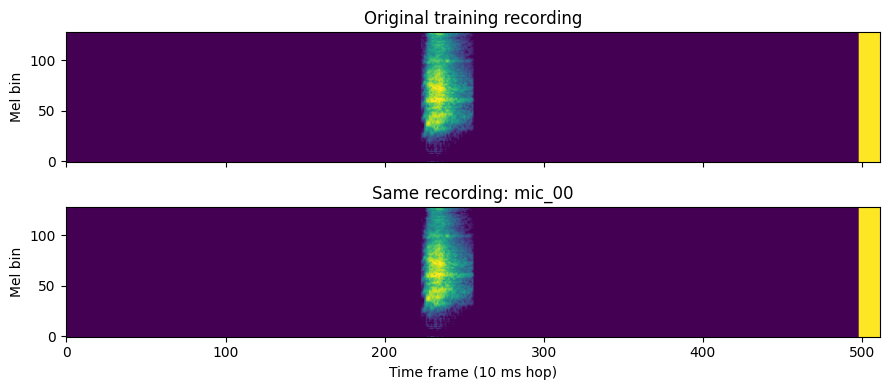

In [6]:
FREQUENCIES=[0,80,250,1000,3000,6000,8000]
GAINS_DB=[
 [0,0,0,-1,-3,-6,-8], [-8,-6,-3,0,0,0,0], [-3,-2,0,3,1,-2,-4],
 [2,2,1,0,-1,-2,-3], [-2,-1,0,-3,2,3,1], [0,1,2,0,-2,1,0],
 [-5,-4,-1,2,0,-3,-5], [1,1,-2,0,3,1,-2],
 [0,0,-2,-3,-5,-9,-12], [-12,-8,-4,-1,1,2,2],
 [-4,-2,2,4,-1,-4,-6], [3,2,-3,-2,4,2,-3],
]
FILTER_CONFIG={f"mic_{i:02d}":dict(frequencies=FREQUENCIES,gains_db=gains,taps=129,
    sr=SAMPLE_RATE,rms_match=True,peak_limit=0.999,delay_compensation=True)
    for i,gains in enumerate(GAINS_DB)}
TRAIN_FILTERS=list(FILTER_CONFIG)[:6]
VAL_FILTERS=list(FILTER_CONFIG)[6:8]
TEST_FILTERS=list(FILTER_CONFIG)[8:]
assert not(set(TRAIN_FILTERS)&set(VAL_FILTERS) or set(TRAIN_FILTERS)&set(TEST_FILTERS)
           or set(VAL_FILTERS)&set(TEST_FILTERS))
FILTER_TAPS={name:signal.firwin2(config["taps"],config["frequencies"],
    10**(np.array(config["gains_db"])/20),fs=SAMPLE_RATE) for name,config in FILTER_CONFIG.items()}
filter_audit=[]

def apply_microphone_filter(waveform,view_id,record=False):
    x=np.asarray(waveform,dtype=np.float64);taps=FILTER_TAPS[view_id]
    delay=(len(taps)-1)//2
    filtered=signal.fftconvolve(x,taps,mode="full")[delay:delay+len(x)]
    before=float(np.sqrt(np.mean(x*x)));after=float(np.sqrt(np.mean(filtered*filtered)))
    if after>1e-12: filtered*=before/after
    peak=float(np.max(np.abs(filtered)));limited=peak>0.999
    if limited: filtered*=0.999/peak
    assert len(filtered)==len(x) and np.isfinite(filtered).all()
    assert np.max(np.abs(filtered))<=1.000001
    if record: filter_audit.append(dict(filter=view_id,rms_original=before,
        rms_filtered=float(np.sqrt(np.mean(filtered*filtered))),rms_match_limited=limited))
    return filtered.astype(np.float32)

def two_training_filters(filename):
    local_seed=int(hashlib.sha256(("assignment_v1:"+filename).encode()).hexdigest()[:8],16)
    return np.random.default_rng(local_seed).choice(TRAIN_FILTERS,size=2,replace=False).tolist()

def make_views(frame,kind):
    rows=[]
    for _,row in frame.iterrows():
        views=(["clean"]+two_training_filters(row.filename) if kind=="train" else
               VAL_FILTERS if kind=="val" else TEST_FILTERS)
        for view in views:
            rec=row.to_dict();rec["view_id"]=view;rows.append(rec)
    return pd.DataFrame(rows).reset_index(drop=True)


dev_filter=TRAIN_FILTERS[0]
filtered=apply_microphone_filter(example_audio,dev_filter,record=True)
fig,axes=plt.subplots(2,1,figsize=(9,4),sharex=True);specs=[logmel(x,False).numpy().T for x in (example_audio,filtered)]
lo,hi=np.percentile(np.stack(specs),[2,98])
for ax,s,title in zip(axes,specs,['Original training recording','Same recording: '+dev_filter]):
    ax.imshow(s,origin='lower',aspect='auto',vmin=lo,vmax=hi);ax.set(ylabel='Mel bin',title=title)
axes[-1].set_xlabel('Time frame (10 ms hop)');fig.tight_layout();fig.savefig(RUN_DIR/'clean_vs_filtered.png',dpi=160);plt.show()


In [7]:
def atomic_npy(path,arr):
    tmp=path.with_suffix('.part')
    with tmp.open('wb') as f:np.save(f,arr,allow_pickle=False)
    tmp.replace(path)

# Step 4 defines this function for filtered views. Clean extraction needs no filter bank.
def transform_waveform(waveform, view_id):
    if view_id == "clean": return waveform
    return apply_microphone_filter(waveform, view_id)

def prior_feature(path):
    # Look up the same content-addressed key. Never write into the previous run.
    older=ROOT.parent/'cisc473_audio'/'feature_cache'/path.name
    if path.is_file() or not older.is_file():return
    try:
        z=np.load(older,allow_pickle=False)
        if z.shape==(768,) and np.isfinite(z).all():atomic_npy(path,z)
    except (OSError,ValueError,EOFError):pass  # recompute in the new folder

def extract_features(frame):
    """Rows require filename, path, audio_sha256, label, view_id, src_file, split."""
    torch.set_num_threads(EXTRACTION_THREADS)
    result=[]; started=time.perf_counter(); computed=0
    for row in tqdm(frame.itertuples(),total=len(frame),desc="AST feature cache"):
        filt = None if row.view_id == "clean" else FILTER_CONFIG[row.view_id]
        key=digest(dict(signature=feature_signature,audio_sha256=row.audio_sha256,
                        view=row.view_id,filter=filt))
        destination=CACHE_DIR/(key+".npy")
        prior_feature(destination)
        if destination.exists():
            z=np.load(destination,allow_pickle=False)
            assert z.shape==(768,) and np.isfinite(z).all(), f"Invalid cache: {destination}"
        else:
            waveform=transform_waveform(load_audio(row.path),row.view_id)
            z=embed_waveform(waveform);computed+=1
            temporary=destination.with_suffix(".tmp")
            with temporary.open("wb") as f: np.save(f,z,allow_pickle=False)
            temporary.replace(destination)
        result.append(z)
    elapsed=time.perf_counter()-started
    print(f"{len(result)} rows; {computed} newly computed; {elapsed:.1f} seconds.")
    return np.stack(result).astype(np.float32)


In [8]:
LABELS=np.arange(N_CLASSES)

def metrics(y,p):
    return {"accuracy":float(accuracy_score(y,p)),
            "macro_f1":float(f1_score(y,p,labels=LABELS,average="macro",zero_division=0))}

@torch.inference_mode()
def predict_head(head,X):
    return head(torch.as_tensor(np.asarray(X),dtype=torch.float32)).argmax(1).numpy()

@torch.inference_mode()
def validation_score(head,X,y,groups=None):
    logits=head(torch.as_tensor(np.asarray(X),dtype=torch.float32))
    predictions=logits.argmax(1).numpy()
    if groups is None: groups=np.zeros(len(y),dtype=int)
    score=np.mean([metrics(y[groups==g],predictions[groups==g])["macro_f1"] for g in np.unique(groups)])
    loss=nn.functional.cross_entropy(logits,torch.as_tensor(y,dtype=torch.long)).item()
    return float(score),float(loss)

def _train_head(X,y,V,vy,seed,l2,groups=None):
    torch.set_num_threads(1)
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    head=nn.Linear(X.shape[1],N_CLASSES)
    optimizer=torch.optim.Adam(head.parameters(),lr=LR)
    Xt=torch.as_tensor(np.asarray(X),dtype=torch.float32)
    yt=torch.as_tensor(y,dtype=torch.long)
    generator=torch.Generator().manual_seed(seed)
    best_key=(-np.inf,-np.inf);best_state=None;history=[];stale=0
    for epoch in range(1,MAX_EPOCHS+1):
        head.train();total=0.0
        for batch in torch.randperm(len(y),generator=generator).split(HEAD_BATCH):
            optimizer.zero_grad(set_to_none=True)
            logits=head(Xt[batch])
            ce=nn.functional.cross_entropy(logits,yt[batch])
            loss=ce+l2*head.weight.square().sum()
            loss.backward();optimizer.step();total+=float(ce.detach())*len(batch)
        head.eval()
        score,val_ce=validation_score(head,V,vy,groups)
        history.append(dict(epoch=epoch,train_ce=total/len(y),val_ce=val_ce,val_macro_f1=score))
        key=(score,-val_ce)
        if key>best_key:
            best_key=key;best_state=copy.deepcopy(head.state_dict());best_epoch=epoch;stale=0
        else: stale+=1
        if stale>=PATIENCE: break
    head.load_state_dict(best_state);head.eval()
    return dict(head=head,score=best_key[0],val_ce=-best_key[1],epoch=best_epoch,
                l2=float(l2),seed=int(seed),history=pd.DataFrame(history))


def train_head(*args,**kwargs):
    threads=torch.get_num_threads()
    try:return _train_head(*args,**kwargs)
    finally:torch.set_num_threads(threads)


In [9]:
def nonzero_basis(rows):
    rows=np.asarray(rows,dtype=np.float64)
    with threadpool_limits(limits=1): _,s,Vt=np.linalg.svd(rows,full_matrices=False)
    tol=max(rows.shape)*np.finfo(np.float64).eps*(s[0] if len(s) else 0)
    return Vt[s>tol].T.copy()

class ChannelProjection:
    def __init__(self,rank=0,protect=True):
        self.requested_rank=int(rank);self.protect=bool(protect)
    def fit(self,original,y,differences):
        original=np.asarray(original,dtype=np.float64)
        self.mean=original.mean(axis=0)
        means=np.stack([original[y==c].mean(axis=0)-self.mean for c in np.unique(y)])
        self.Q=nonzero_basis(means)
        D=np.asarray(differences,dtype=np.float64)
        residual=D-(D@self.Q)@self.Q.T if self.protect else D
        basis=nonzero_basis(residual)
        self.available_rank=basis.shape[1]
        self.effective_rank=min(self.requested_rank,self.available_rank)
        U=basis[:,:self.effective_rank]
        if self.protect and U.shape[1]:
            # Remove numerical drift and restore orthonormal columns.
            U=U-self.Q@(self.Q.T@U)
            U=np.linalg.qr(U,mode="reduced")[0]
        self.U=U
        return self
    def transform(self,X):
        centred=np.asarray(X,dtype=np.float64)-self.mean
        return (centred-(centred@self.U)@self.U.T).astype(np.float32)

rng=np.random.default_rng(7)
synthetic_X=rng.normal(size=(90,24));synthetic_y=np.repeat(np.arange(3),30)
synthetic_D=rng.normal(size=(180,24))
check=ChannelProjection(4,True).fit(synthetic_X,synthetic_y,synthetic_D)
np.testing.assert_allclose(check.Q.T@check.U,0,atol=1e-10)
np.testing.assert_allclose(check.U.T@check.U,np.eye(4),atol=1e-10)
P=np.eye(24)-check.U@check.U.T
np.testing.assert_allclose(P@P,P,atol=1e-10)
transformed=check.transform(synthetic_X)
for cls in np.unique(synthetic_y):
    np.testing.assert_allclose(transformed[synthetic_y==cls].mean(0),
        synthetic_X[synthetic_y==cls].mean(0)-check.mean,atol=1e-6)
identity=ChannelProjection(0,True).fit(synthetic_X,synthetic_y,synthetic_D)
np.testing.assert_allclose(identity.transform(synthetic_X),synthetic_X-identity.mean,atol=1e-6)
print("Passed: orthogonality, orthonormality, idempotence, class-mean preservation, rank-zero identity.")


Passed: orthogonality, orthonormality, idempotence, class-mean preservation, rank-zero identity.


In [10]:
# Final experiment utilities. Each outer fold has its own saved evidence.
def split_fold(frame, fold):
    folds=sorted(frame.fold.unique()); val=folds[(folds.index(fold)+1)%len(folds)]
    tr=frame[~frame.fold.isin([fold,val])].copy(); va=frame[frame.fold.eq(val)].copy(); te=frame[frame.fold.eq(fold)].copy()
    for a,b in [(tr,va),(tr,te),(va,te)]: assert not set(a.src_file)&set(b.src_file)
    return tr,va,te

def fixed_head(X,y,seed,l2,epochs):
    torch.manual_seed(seed); head=nn.Linear(X.shape[1],N_CLASSES)
    opt=torch.optim.Adam(head.parameters(),lr=LR); gen=torch.Generator().manual_seed(seed)
    X=torch.tensor(X,dtype=torch.float32);y=torch.tensor(y,dtype=torch.long); history=[]
    for epoch in range(epochs):
        total=0
        for idx in torch.randperm(len(y),generator=gen).split(HEAD_BATCH):
            opt.zero_grad(); ce=nn.functional.cross_entropy(head(X[idx]),y[idx]); loss=ce+l2*head.weight.square().sum()
            loss.backward();opt.step();total+=ce.item()*len(idx)
        history.append({'epoch':epoch+1,'train_ce':total/len(y)})
    return head.eval(),pd.DataFrame(history)

def build_projection(family,k,X,y,D,seed):
    p=ChannelProjection(k,family in ['cpcp','unpaired']).fit(X,y,D)
    if family=='random':
        r=np.random.default_rng(seed).normal(size=(X.shape[1],min(k,X.shape[1])))
        p.U=np.linalg.qr(r,mode='reduced')[0];p.effective_rank=p.U.shape[1]
    if family=='class_means':
        p.U=nonzero_basis(np.eye(X.shape[1])-p.Q@p.Q.T);p.effective_rank=p.U.shape[1]
    return p

def bundle(frame):
    original=extract_features(frame.assign(view_id='clean'))
    views=make_views(frame,'train'); aug=extract_features(views)
    ix={f:i for i,f in enumerate(frame.filename)}
    mask=views.view_id.ne('clean').to_numpy()
    aligned=original[[ix[f] for f in views.loc[mask,'filename']]]
    return original,views,aug,aug[mask]-aligned

def records(frame,pred,method,seed,fold):
    out=frame[['filename','src_file','label','view_id']].copy()
    out['prediction']=pred;out['method']=method;out['seed']=seed;out['outer_fold']=fold
    return out

def run_core(frame,dataset,folds=None,secondary=False):
    global N_CLASSES,LABELS
    N_CLASSES=frame.label.nunique();LABELS=np.arange(N_CLASSES)
    families=['original_only','augmentation_only','unprotected','cpcp']
    if secondary: families+=['random','class_means','unpaired']
    for fold in (folds or sorted(frame.fold.unique())):
        dest=FINAL_DIR/dataset/f'fold_{fold}';dest.mkdir(parents=True,exist_ok=True)
        pending=[s for s in SEEDS if not prediction_path(dataset,fold,s).exists()]
        if not pending:
            print(dataset,fold,': all seeds already saved.');continue
        print(dataset,'fold',fold,'pending seeds:',pending,flush=True)
        tr,va,te=split_fold(frame,fold)
        for split,f in [('train',tr),('val',va),('test',te)]:f.to_csv(dest/f'{split}.csv',index=False)
        X,views,A,D=bundle(tr);y=tr.label.to_numpy();ya=views.label.to_numpy()
        V=extract_features(va.assign(view_id='clean'));yv=va.label.to_numpy()
        vf=make_views(va,'val');VF=extract_features(vf);yvf=vf.label.to_numpy();groups=vf.view_id.to_numpy()
        # Validation is used for selection only. Refit includes it after settings are fixed.
        ref=pd.concat([tr,va],ignore_index=True);RX,rv,RA,RD=bundle(ref);ry=ref.label.to_numpy();ray=rv.label.to_numpy()
        test=pd.concat([te.assign(view_id='clean'),make_views(te,'test')],ignore_index=True)
        T=extract_features(test)
        bases={}
        def projection(family,k,phase,X0,y0,D0,seed):
            if family not in CORE:return build_projection(family,k,X0,y0,D0,seed)
            if k==0:
                p=ChannelProjection(0,False);p.mean=np.asarray(X0,dtype=np.float64).mean(0);p.U=np.empty((X0.shape[1],0));p.effective_rank=0;return p
            key=(phase,family)
            if key not in bases:bases[key]=build_projection(family,max(RANK_GRID),X0,y0,D0,seed)
            p=copy.copy(bases[key]);p.U=p.U[:,:k];p.effective_rank=p.U.shape[1];return p
        for seed in pending:
            output=dest/f'predictions_seed{seed}.csv'
            if output.exists(): print('Resume: completed',output);continue
            seed_started=time.perf_counter()
            allpred=[]; selections=[]; baseline_clean=None
            for family in tqdm(families,desc=f"Fold {fold}, seed {seed}"):
                candidates=[]
                ranks=[0] if family in ['original_only','augmentation_only','class_means'] else RANK_GRID
                DD=D; RDD=RD
                if family=='unpaired':
                    rng=np.random.default_rng(seed)
                    # Keep filtered rows fixed, shuffle their original partners only.
                    mask=views.view_id.ne('clean').to_numpy();ids={f:i for i,f in enumerate(tr.filename)}
                    orig=X[[ids[f] for f in views.loc[mask,'filename']]]
                    DD=A[mask]-orig[rng.permutation(len(orig))]
                    mask=rv.view_id.ne('clean').to_numpy();ids={f:i for i,f in enumerate(ref.filename)}
                    orig=RX[[ids[f] for f in rv.loc[mask,'filename']]]
                    RDD=RA[mask]-orig[rng.permutation(len(orig))]
                for k in ranks:
                    p=projection(family,k,"train",X,y,DD,seed)
                    B,by=(X,y) if family=='original_only' else (A,ya)
                    val,vy,gg=(V,yv,None) if family=='original_only' else (VF,yvf,groups)
                    BP,VP,CP=p.transform(B),p.transform(val),p.transform(V)
                    for l2 in L2_GRID:
                        c=train_head(BP,by,VP,vy,seed,l2,gg)
                        clean=metrics(yv,predict_head(c['head'],CP))['accuracy']
                        eligible=family not in ['unprotected','cpcp','random','class_means','unpaired'] or clean>=baseline_clean-CLEAN_TOLERANCE-1e-12
                        c.update(k=k,clean=clean,eligible=eligible)
                        c['history'].to_csv(dest/f'search_{family}_{seed}_{k}_{l2}.csv',index=False)
                        if eligible:candidates.append(c)
                # Rank zero guarantees fallback for projection families; class-only can fail the clean constraint.
                if not candidates:
                    selections.append(dict(method=family,status='no validation-eligible candidate'));continue
                best=max(candidates,key=lambda c:(c['score'],-c['val_ce'],-c['k']))
                if family=='augmentation_only':baseline_clean=best['clean']
                p=projection(family,best['k'],'refit',RX,ry,RDD,seed)
                B,by=(RX,ry) if family=='original_only' else (RA,ray)
                head,hist=fixed_head(p.transform(B),by,seed,best['l2'],best['epoch'])
                pred=predict_head(head,p.transform(T));allpred.append(records(test,pred,family,seed,fold))
                np.savez_compressed(dest/f'{family}_{seed}.npz',weight=head.weight.detach().numpy(),bias=head.bias.detach().numpy(),mean=p.mean,U=p.U)
                hist.to_csv(dest/f'refit_{family}_{seed}.csv',index=False)
                selections.append(dict(method=family,rank=p.effective_rank,l2=best['l2'],epochs=best['epoch'],validation_f1=best['score']))
            save_json(dest/f'selection_seed{seed}.json',selections)
            import resource
            save_json(dest/f'timing_seed{seed}.json',dict(seconds=time.perf_counter()-seed_started,peak_rss_raw=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss,units='bytes on macOS; KiB on Linux; process lifetime maximum'))
            temporary=output.with_suffix('.tmp')
            pd.concat(allpred).to_csv(temporary,index=False);temporary.replace(output)
            print(dataset,fold,seed,'saved')

def score_predictions(df):
    rows=[]
    for (method,seed,fold),g in df.groupby(['method','seed','outer_fold']):
        clean=g[g.view_id.eq('clean')]; filtered=g[~g.view_id.eq('clean')]
        fs=[metrics(v.label,v.prediction)['macro_f1'] for _,v in filtered.groupby('view_id')]
        rows.append(dict(method=method,seed=seed,fold=fold,clean_accuracy=metrics(clean.label,clean.prediction)['accuracy'],
            clean_macro_f1=metrics(clean.label,clean.prediction)['macro_f1'],filter_macro_f1=np.mean(fs),worst_filter_macro_f1=min(fs)))
    return pd.DataFrame(rows)

CORE=('original_only','augmentation_only','unprotected','cpcp')
CONTROLS=('random','class_means','unpaired')
def prediction_path(dataset,fold,seed):
    p=Path(f'fold_{fold}')/f'predictions_seed{seed}.csv'
    new=FINAL_DIR/dataset/p
    if new.exists():return new
    return new

def atomic_csv(df,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix('.part');df.to_csv(tmp,index=False);tmp.replace(path)

def final_tables(dataset,expected_folds,frame):
    global LABELS,N_CLASSES
    LABELS=np.sort(frame.label.unique());N_CLASSES=len(LABELS)
    root=FINAL_DIR/dataset;root.mkdir(exist_ok=True,parents=True)
    groups=[];audit=[]
    for fold in expected_folds:
        reference=frame[frame.fold.eq(fold)][['filename','label','src_file']].copy()
        reference['src_file']=reference.src_file.astype(str)
        expected=reference.merge(pd.DataFrame({'view_id':['clean',*TEST_FILTERS]}),how='cross')
        keys=['filename','view_id','label','src_file']
        idx=pd.MultiIndex.from_frame(expected[keys])
        for seed in SEEDS:
            p=prediction_path(dataset,fold,seed)
            data=pd.read_csv(p,dtype={'src_file':str}) if p.exists() else pd.DataFrame(columns=['method'])
            for method in (*CORE,*(CONTROLS if RUN_SECONDARY else ())):
                g=data[data.method.eq(method)]
                ok=(len(g)==len(idx) and g.seed.eq(seed).all() and g.outer_fold.eq(fold).all()
                    and g.prediction.isin(LABELS).all() and pd.MultiIndex.from_frame(g[keys]).is_unique
                    and len(idx.difference(pd.MultiIndex.from_frame(g[keys])))==0)
                audit.append(dict(method=method,seed=seed,fold=fold,complete=bool(ok),rows=len(g)))
                if ok:groups.append(g)
    cov=pd.DataFrame(audit);atomic_csv(cov,root/'method_coverage.csv')
    bad=cov[~cov.complete];core_bad=bad[bad.method.isin(CORE)]
    if len(core_bad):raise ValueError('Incomplete required predictions. See '+str(root/'method_coverage.csv')+'\n'+core_bad.to_string(index=False))
    if len(bad):print('Optional methods excluded from aggregate if any fold/seed is missing:');display(bad)
    df=pd.concat(groups,ignore_index=True);df=df[~df.method.isin(bad.method)].copy()
    scores=score_predictions(df);atomic_csv(scores,root/'fold_scores.csv')
    cols=['clean_accuracy','clean_macro_f1','filter_macro_f1','worst_filter_macro_f1']
    per_seed=scores.groupby(['method','seed'])[cols].mean()
    summary=per_seed.groupby('method').agg(['mean','std'])*100
    summary.to_csv(root/'summary_percent.csv');display(summary.round(2))
    from sklearn.metrics import recall_score
    rows=[]
    for (method,seed,fold,view),g in df.groupby(['method','seed','outer_fold','view_id']):
        rec=recall_score(g.label,g.prediction,labels=LABELS,average=None,zero_division=0)
        rows.extend(dict(method=method,seed=seed,fold=fold,view=view,label=int(c),recall=v) for c,v in zip(LABELS,rec))
    atomic_csv(pd.DataFrame(rows),root/'class_recall.csv')
    return df

def paired_bootstrap(df,n=2000):
    """Resample complete source recordings; aggregate sparse per-source class counts."""
    from scipy.sparse import coo_matrix
    rng=np.random.default_rng(2026);fold_draws=[];point=[]
    sub=df[df.method.isin(['augmentation_only','cpcp']) & df.view_id.ne('clean')]
    for fold,g in tqdm(sub.groupby('outer_fold'),desc='Bootstrap folds'):
        sources,ix=np.unique(g.src_file,return_inverse=True)
        methods=['augmentation_only','cpcp'];seeds=sorted(g.seed.unique());views=sorted(g.view_id.unique())
        labels=np.sort(df.label.unique());C=len(labels);K=2*len(seeds)*len(views)
        k=(g.method.map(dict(zip(methods,range(2)))).to_numpy()*len(seeds)+np.searchsorted(seeds,g.seed))*len(views)+np.searchsorted(views,g.view_id)
        y=np.searchsorted(labels,g.label);p=np.searchsorted(labels,g.prediction);hit=y==p
        col=np.r_[k*3*C+y,k*3*C+C+p,k[hit]*3*C+2*C+y[hit]]
        row=np.r_[ix,ix,ix[hit]]
        counts=coo_matrix((np.ones(len(col)),(row,col)),shape=(len(sources),K*3*C)).tocsr()
        def difference(weights):
            a=(counts.T@weights.T).T.reshape(-1,2,len(seeds),len(views),3,C)
            den=a[...,0,:]+a[...,1,:];tp=a[...,2,:]
            scores=np.divide(2*tp,den,out=np.zeros_like(tp),where=den!=0).mean(axis=(-1,-2,-3))
            return (scores[:,1]-scores[:,0])*100
        point.append(difference(np.ones((1,len(sources))))[0])
        fold_draws.append(np.concatenate([difference(rng.multinomial(len(sources),np.ones(len(sources))/len(sources),size=min(64,n-i))) for i in range(0,n,64)]))
    d=np.mean(fold_draws,axis=0)
    return dict(difference_pp=float(np.mean(point)),low=float(np.percentile(d,2.5)),high=float(np.percentile(d,97.5)),resamples=n,contrast='CPCP minus augmentation only: average held-out-filter macro F1, percentage points',interpretation='Recording-sampling uncertainty conditional on fitted runs.')


In [11]:
URBAN_URL='https://zenodo.org/records/1203745/files/UrbanSound8K.tar.gz'
URBAN_MD5='9aa69802bbf37fb986f71ec1483a196e'
def locate_urban(root):
    for d in dict.fromkeys([Path(root),Path(root)/'UrbanSound8K',ROOT/'data/UrbanSound8K',ROOT.parent/'UrbanSound8K',ROOT.parent/'cisc473_audio/UrbanSound8K',ROOT.parent/'cisc473_audio/UrbanSound8K/UrbanSound8K']):
        p=d/'metadata/UrbanSound8K.csv'
        if not p.is_file():continue
        f=pd.read_csv(p)
        if len(f)==8732 and all((d/'audio'/f'fold{r.fold}'/r.slice_file_name).is_file() for r in f.itertuples()):return d
    return None

def prepare_urban(root,download):
    import tarfile,re
    d=locate_urban(root)
    if d is not None:return d
    root=Path(root);root.mkdir(exist_ok=True,parents=True)
    archive=next((p for p in [root/'UrbanSound8K.tar.gz',ROOT/'UrbanSound8K.tar.gz',ROOT.parent/'UrbanSound8K.tar.gz'] if p.is_file()),None)
    if archive is None and download:
        tmp=root/'UrbanSound8K.tar.gz.part'
        print('UrbanSound8K: resuming the official 6 GB archive; this attempt is limited to 10 min. Existing bytes:',tmp.stat().st_size if tmp.exists() else 0,flush=True)
        try:
            subprocess.run(['curl','--fail','--location','--continue-at','-','--connect-timeout','20','--speed-limit','1024','--speed-time','60','--max-time','600','--output',str(tmp),URBAN_URL],check=True,timeout=620)
        except (subprocess.SubprocessError,OSError) as ex:
            print('Download paused:',ex,'; rerun section 7 to resume or extract the archive manually.');return None
        archive=tmp
    if archive is None:return None
    with archive.open('rb') as f:checksum=hashlib.file_digest(f,'md5').hexdigest()
    if checksum!=URBAN_MD5:
        print('Incomplete or corrupt archive:',archive,'; use the official download and verify its MD5.');return None
    if archive.suffix=='.part':
        archive=archive.rename(archive.with_suffix(''))
    # Write only known dataset members; an interrupted extraction is safe to repeat.
    with tarfile.open(archive,'r|gz') as tar:
        for m in tqdm(tar,desc='Extracting archive members'):
            name=m.name.removeprefix('./').removeprefix('UrbanSound8K/')
            if not m.isfile() or not re.fullmatch(r'(metadata/UrbanSound8K\.csv|audio/fold(?:[1-9]|10)/[0-9-]+\.wav)',name):continue
            dest=root/name;dest.parent.mkdir(parents=True,exist_ok=True)
            if dest.exists() and dest.stat().st_size==m.size:continue
            temp=dest.with_suffix('.part')
            with temp.open('wb') as f:shutil.copyfileobj(tar.extractfile(m),f)
            temp.replace(dest)
    return locate_urban(root)

def urban_manifest(root):
    f=pd.read_csv(root/'metadata/UrbanSound8K.csv').rename(columns={'slice_file_name':'filename','fsID':'src_file','classID':'label','class':'category'})
    assert f.filename.is_unique and len(f)==8732 and set(f.fold)==set(range(1,11)) and set(f.label)==set(range(10))
    f['path']=[str(root/'audio'/f'fold{r.fold}'/r.filename) for r in f.itertuples()]
    counts=f.groupby('src_file').fold.nunique()
    skip=f.src_file.isin(counts[counts>1].index);atomic_csv(f[skip],FINAL_DIR/'urban_source_exclusions.csv')
    f=f[~skip].copy()
    p=FINAL_DIR/'urban_manifest.csv';prior=pd.read_csv(p).set_index('filename').to_dict('index') if p.exists() else {}
    rows=[]
    for r in tqdm(f.itertuples(),total=len(f),desc='Verify Urban audio'):
        st=Path(r.path).stat();old=prior.get(r.filename,{})
        if (old.get('path'),old.get('bytes'),old.get('mtime_ns'))==(r.path,st.st_size,st.st_mtime_ns):h=old['audio_sha256']
        else:
            if sf.info(r.path).frames<=0:raise ValueError('Empty audio: '+r.path)
            h=file_sha256(r.path)
        rows.append((h,st.st_size,st.st_mtime_ns))
    f[['audio_sha256','bytes','mtime_ns']]=pd.DataFrame(rows,index=f.index)
    atomic_csv(f,p);return f

def spectrum(row):
    # Very short UrbanSound clips are padded before Kaldi framing.
    x=load_audio(row.path)
    if len(x)<400:x=np.pad(x,(0,400-len(x)))
    return logmel(x)

def spec_mask(x,kind,seed):
    x=x.clone();g=torch.Generator().manual_seed(seed)
    for axis,limit in [(0,64),(1,16)]:
        if (axis==0 and kind not in ['time','both']) or (axis==1 and kind not in ['frequency','both']):continue
        width=int(torch.randint(0,min(limit,x.shape[axis])+1,(1,),generator=g))
        start=int(torch.randint(0,x.shape[axis]-width+1,(1,),generator=g))
        if axis==0:x[start:start+width,:]=0
        else:x[:,start:start+width]=0
    return x

def freq_mixstyle(x,partner,seed):
    # Per-frequency statistics over TIME, mixed only with a training partner.
    rng=np.random.default_rng(seed);lam=float(rng.beta(.3,.3))
    mu=x.mean(0,keepdim=True);sd=x.var(0,unbiased=False,keepdim=True).add(1e-6).sqrt()
    pm=partner.mean(0,keepdim=True);ps=partner.var(0,unbiased=False,keepdim=True).add(1e-6).sqrt()
    return (x-mu)/sd*(lam*sd+(1-lam)*ps)+(lam*mu+(1-lam)*pm)

@torch.inference_mode()
def augmented_features(frame,kind,seed=42,count=2):
    out=[];ys=[];pool=frame.reset_index(drop=True)
    for r in tqdm(pool.itertuples(),total=len(pool),desc=kind):
        for view in range(count):
            local=int(digest([r.audio_sha256,kind,seed,view])[:8],16)
            partner=pool.iloc[local%len(pool)]
            key=digest(dict(signature=feature_signature,kind=kind,seed=local,count=count,
                audio=r.audio_sha256,partner=partner.audio_sha256 if kind=='filter_freqmix' else None,
                filters=FILTER_CONFIG if kind=='filter_freqmix' else None,version='final-v1'))
            path=CACHE_DIR/(key+'.npy')
            prior_feature(path)
            if path.exists():z=np.load(path,allow_pickle=False)
            else:
                if kind=='filter_freqmix':
                    filt=two_training_filters(r.filename)[view%2]
                    x=logmel(apply_microphone_filter(load_audio(r.path),filt));x=freq_mixstyle(x,spectrum(partner),local)
                else:x=spec_mask(spectrum(r),kind,local)
                z=ast_model(x[None].to(DEVICE)).pooler_output[0].cpu().numpy();atomic_npy(path,z)
            assert z.shape==(768,) and np.isfinite(z).all()
            out.append(z);ys.append(r.label)
    return np.asarray(out),np.asarray(ys)

class MelCNN(nn.Module):
    def __init__(self,classes):
        super().__init__();layers=[];inc=1
        for outc in [16,32,64]:
            layers += [nn.Conv2d(inc,outc,3,padding=1),nn.BatchNorm2d(outc),nn.ReLU(),nn.MaxPool2d(2)];inc=outc
        self.net=nn.Sequential(*layers,nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Linear(64,classes))
    def forward(self,x):return self.net(x.unsqueeze(1))

class TunedAST(nn.Module):
    def __init__(self,classes,patch=16):
        super().__init__();self.backbone=copy.deepcopy(ast_model).requires_grad_(True)
        if patch!=16:
            # Interpolate pretrained convolution kernels and positional grid, preserving special tokens.
            emb=self.backbone.embeddings;old=emb.patch_embeddings.projection
            conv=nn.Conv2d(1,768,patch,stride=old.stride,bias=True).to(DEVICE)
            with torch.no_grad():
                conv.weight.copy_(nn.functional.interpolate(old.weight,size=(patch,patch),mode='bicubic',align_corners=False)*(16/patch)**2)
                conv.bias.copy_(old.bias)
            emb.patch_embeddings.projection=conv
            oldf=(128-16)//10+1;oldt=(FRAMES-16)//10+1;nf=(128-patch)//10+1;nt=(FRAMES-patch)//10+1
            pos=emb.position_embeddings.detach();grid=pos[:,2:].reshape(1,oldf,oldt,768).permute(0,3,1,2)
            grid=nn.functional.interpolate(grid,size=(nf,nt),mode='bilinear',align_corners=False).permute(0,2,3,1).reshape(1,nf*nt,768)
            emb.position_embeddings=nn.Parameter(torch.cat([pos[:,:2],grid],1));self.backbone.config.patch_size=patch
        self.head=nn.Linear(768,classes).to(DEVICE)
    def forward(self,x):return self.head(self.backbone(x).pooler_output)

class AudioDataset(torch.utils.data.Dataset):
    def __init__(self,frame):self.frame=frame.reset_index(drop=True)
    def __len__(self):return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i];key=digest(dict(audio=r.audio_sha256,preprocess=preprocessing_signature))
        p=SPEC_DIR/(key+'.npy')
        if not p.exists():atomic_npy(p,spectrum(r).numpy())
        return torch.from_numpy(np.load(p)),int(r.label)

@torch.inference_mode()
def attention_check(row,head_file,output):
    """Frozen AST final-layer token attention; perturb the same head, no test tuning."""
    # Reload architecture with eager attention instead of mutating SDPA modules in-place.
    config=copy.deepcopy(ast_model.config);config._attn_implementation='eager'
    from transformers import ASTModel
    eager=ASTModel(config).to(DEVICE);eager.load_state_dict(ast_model.state_dict());eager.eval()
    x=spectrum(row).to(DEVICE);result=eager(x[None],output_attentions=True)
    att=result.attentions[-1][0].mean(0)[:2,2:].mean(0)
    nf=(MEL_BINS-16)//10+1;nt=(FRAMES-16)//10+1;grid=att.reshape(nf,nt).cpu().numpy()
    h=np.load(head_file)
    def score(inp):
        z=eager(inp[None]).pooler_output.cpu().numpy()-h['mean'];z=z-(z@h['U'])@h['U'].T
        logits=z@h['weight'].T+h['bias'];prob=torch.softmax(torch.tensor(logits),1).numpy()[0];return prob
    clean=score(x);cls=int(clean.argmax());rng=np.random.default_rng(42);count=max(1,int(.1*att.numel()))
    values=[]
    for name,idx in [('top',np.argsort(grid.ravel())[-count:]),('random',rng.choice(att.numel(),count,False))]:
        pert=x.clone()
        for i in idx:f,t=divmod(int(i),nt);pert[t*10:t*10+16,f*10:f*10+16]=0
        prob=score(pert);values.append(dict(region=name,prediction=int(prob.argmax()),original_class=cls,probability_drop=float(clean[cls]-prob[cls])))
    fig,ax=plt.subplots();ax.imshow(grid,origin='lower',aspect='auto');ax.set(xlabel='Time patch',ylabel='Frequency patch',title='Final-layer special-token attention')
    fig.savefig(str(output)+'.png',dpi=180);plt.show();pd.DataFrame(values).to_csv(str(output)+'.csv',index=False)
    del eager

def transfer(urban,esc):
    global N_CLASSES,LABELS
    N_CLASSES=3;LABELS=np.arange(3)
    if all((FINAL_DIR/f'transfer_{s}.csv').exists() for s in SEEDS):return
    mappings={'dog_bark':0,'siren':1,'car_horn':2};targets={'dog':0,'siren':1,'car_horn':2}
    u=urban[urban.category.isin(mappings)].copy();e=esc[esc.category.isin(targets)].copy()
    # Freesound IDs identify shared recordings even if files differ in length/encoding.
    excluded=e[e.src_file.astype(str).isin(u.src_file.astype(str))];excluded.to_csv(FINAL_DIR/'transfer_excluded.csv',index=False)
    e=e[~e.src_file.astype(str).isin(u.src_file.astype(str))].copy()
    e=e[~e.audio_sha256.isin(u.audio_sha256)].copy();u['label']=u.category.map(mappings);e['label']=e.category.map(targets)
    assert e.label.nunique()==3 and u.label.nunique()==3
    atomic_csv(u,FINAL_DIR/'transfer_source_manifest.csv');atomic_csv(e,FINAL_DIR/'transfer_target_manifest.csv')
    tr=u[u.fold.ne(10)];va=u[u.fold.eq(10)];X=extract_features(tr.assign(view_id='clean'));V=extract_features(va.assign(view_id='clean'))
    A=extract_features(u.assign(view_id='clean'));T=extract_features(e.assign(view_id='clean'))
    for seed in SEEDS:
        mu=X.mean(0);best=max([train_head(X-mu,tr.label.to_numpy(),V-mu,va.label.to_numpy(),seed,l2) for l2 in L2_GRID],key=lambda c:(c['score'],-c['val_ce']))
        mean=A.mean(0);h,hist=fixed_head(A-mean,u.label.to_numpy(),seed,best['l2'],best['epoch'])
        pred=records(e.assign(view_id='clean'),predict_head(h,T-mean),'shared_class_transfer',seed,0)
        np.savez(FINAL_DIR/f'transfer_{seed}.npz',weight=h.weight.detach().numpy(),bias=h.bias.detach().numpy(),mean=mean)
        save_json(FINAL_DIR/f'transfer_settings_{seed}.json',dict(l2=best['l2'],epochs=best['epoch'],mapping=targets))
        atomic_csv(pred,FINAL_DIR/f'transfer_{seed}.csv')
    print('Shared-class cross-dataset transfer; no ESC-50 tuning. This is not unseen-label zero-shot learning.')

def set_labels(frame):
    global N_CLASSES,LABELS
    LABELS=np.sort(frame.label.unique());N_CLASSES=len(LABELS)
    assert np.array_equal(LABELS,np.arange(N_CLASSES))

def clean_and_masked(frame,dataset,kinds):
    """Clip-local fixed transforms only. No training statistic is fitted across folds."""
    set_labels(frame);frame=frame.reset_index(drop=True)
    folds=sorted(frame.fold.unique())
    units=[(fold,k,seed,aux_dir(dataset,k,fold,seed)/f'predictions_{seed}.csv') for fold in folds for k in kinds for seed in SEEDS]
    todo=[u for u in units if not u[3].is_file()]
    if not todo:print(dataset,': all requested head predictions already saved.');return
    clean=extract_features(frame.assign(view_id='clean'))
    masked={}
    for kind in dict.fromkeys(k for _,k,_,_ in todo if k not in ('frozen_ast','no_mask')):
        torch.set_num_threads(EXTRACTION_THREADS)
        masked[kind]=augmented_features(frame,kind,count=1)[0]
    x=np.arange(len(frame))
    for fold in folds:
        jobs=[j for j in todo if j[0]==fold]
        if not jobs:continue
        train=x[frame.fold.ne(fold)];test=x[frame.fold.eq(fold)]
        te=frame.iloc[test];mu=clean[train].mean(0)
        if dataset=='esc50':
            filtered=make_views(te,'test');T=np.concatenate([clean[test],extract_features(filtered)])
            views=pd.concat([te.assign(view_id='clean'),filtered])
        else:views=te.assign(view_id='clean');T=clean[test]
        for _,k,seed,out in jobs:
            X=clean[train];y=frame.label.to_numpy()[train]
            if k!='frozen_ast':
                X=np.concatenate([X,(clean if k=='no_mask' else masked[k])[train]]);y=np.tile(y,2)
            out.parent.mkdir(exist_ok=True,parents=True)
            head,hist=fixed_head(X-mu,y,seed,HEAD_L2,HEAD_EPOCHS)
            hist.to_csv(out.parent/'history.csv',index=False)
            np.savez(out.parent/'head.npz',weight=head.weight.detach().numpy(),bias=head.bias.detach().numpy(),mean=mu)
            atomic_csv(frame.iloc[train][['filename','src_file','fold','label']],out.parent/'train.csv')
            atomic_csv(records(views,predict_head(head,T-mu),k,seed,fold),out)
            print(dataset,'fold',fold,k,'saved',flush=True)

def balanced_sample(frame,cap,seed):
    if cap is None:return frame.sort_values('filename')
    return pd.concat([g.sort_values('filename').sample(min(cap,len(g)),random_state=seed) for _,g in frame.groupby('label')]).sort_values('filename')

class SmallSpectra(torch.utils.data.Dataset):
    """Materialize pooled CNN inputs once per clip, not every epoch."""
    def __init__(self,frame):
        buf=[];ds=AudioDataset(frame)
        for i in tqdm(range(len(ds)),desc='Prepare compact CNN inputs'):
            r=ds.frame.iloc[i];p=SPEC_DIR/(digest([r.audio_sha256,preprocessing_signature,'meanpool4x4'])+'.npy')
            if not p.exists():
                x=spectrum(r);atomic_npy(p,nn.functional.avg_pool2d(x[None],4)[0].numpy())
            buf.append(np.load(p,allow_pickle=False))
        self.X=torch.from_numpy(np.stack(buf));self.y=torch.as_tensor(frame.label.to_numpy(),dtype=torch.long)
    def __len__(self):return len(self.y)
    def __getitem__(self,i):return self.X[i],self.y[i]

def run_neural_fast(frame,dataset,kind,patch=16,folds=None):
    """Fixed training budget, three independent initializations. No selection on the outer test fold."""
    frame=frame.reset_index(drop=True);set_labels(frame)
    is_ast=kind=='ast';folds=sorted(frame.fold.unique()) if folds is None else folds
    slots=[(fold,seed,aux_dir(dataset,f'{kind}_patch{patch}',fold,seed)) for fold in folds for seed in SEEDS]
    slots=[(f,seed,p) for f,seed,p in slots if not (p/f'predictions_{seed}.csv').exists()]
    if not slots:print(dataset,kind,patch,': already complete.');return
    torch.set_num_threads(EXTRACTION_THREADS)
    ds=AudioDataset(frame) if is_ast else SmallSpectra(frame)
    for fold,seed,dest in slots:
        train=balanced_sample(frame[frame.fold.ne(fold)],AST_PER_CLASS if is_ast else None,SAMPLE_SEED);test=frame[frame.fold.eq(fold)]
        assert set(train.src_file).isdisjoint(test.src_file)
        dest.mkdir(parents=True,exist_ok=True);atomic_csv(train[['filename','src_file','label','fold']],dest/'train.csv')
        batch=2 if is_ast else 32;lr=1e-5 if is_ast else .001;epochs=AST_EPOCHS if is_ast else CNN_EPOCHS
        gen=torch.Generator().manual_seed(seed);torch.manual_seed(seed)
        net=(TunedAST(N_CLASSES,patch) if is_ast else MelCNN(N_CLASSES)).to(DEVICE);opt=torch.optim.AdamW(net.parameters(),lr=lr,weight_decay=1e-4)
        # Populate spectrogram cache before timing so patch 16 is not charged for making the common inputs.
        if is_ast:
            for i in tqdm([*train.index,*test.index],desc='Check common spectrogram inputs'):ds[i]
        def loader(indices,shuffle=False):
            return torch.utils.data.DataLoader(torch.utils.data.Subset(ds,list(indices)),batch_size=batch,shuffle=shuffle,generator=gen)
        print(f'{dataset}, fold {fold}, seed {seed}, {kind} patch {patch}: {len(train)} train, {len(test)} test, {epochs} epoch(s)',flush=True)
        start=time.perf_counter();history=[]
        for ep in range(epochs):
            net.train();loss_sum=0
            for x,y in tqdm(loader(train.index,True),desc=f'fold {fold} epoch {ep+1}/{epochs}'):
                x,y=x.to(DEVICE),y.to(DEVICE);opt.zero_grad(set_to_none=True)
                loss=nn.functional.cross_entropy(net(x),y);loss.backward();opt.step();loss_sum+=loss.item()*len(y)
            history.append(dict(epoch=ep+1,train_ce=loss_sum/len(train)))
        train_seconds=time.perf_counter()-start;net.eval();pred=[];start=time.perf_counter()
        with torch.inference_mode():
            for x,_ in tqdm(loader(test.index),desc='Held-out predictions'):pred.extend(net(x.to(DEVICE)).argmax(1).cpu().tolist())
        infer=time.perf_counter()-start
        atomic_csv(pd.DataFrame(history),dest/'history.csv');torch.save(net.state_dict(),dest/'weights.pt')
        save_json(dest/'timing.json',dict(fold=int(fold),seed=seed,patch=patch,epochs=epochs,lr=lr,
            train_clips=len(train),test_clips=len(test),train_seconds=train_seconds,inference_seconds_per_clip=infer/len(test)))
        atomic_csv(records(test.assign(view_id='clean'),pred,kind,seed,fold),dest/f'predictions_{seed}.csv')
        del net,opt


In [12]:
def run_panns(frame,dataset):
    """Frozen CNN14 clean baseline; native 32 kHz preprocessing, same folds and seeds."""
    global N_CLASSES,LABELS
    from panns_inference.models import Cnn14
    N_CLASSES=frame.label.nunique();LABELS=np.arange(N_CLASSES)
    checkpoint=download_file('https://zenodo.org/records/3987831/files/Cnn14_mAP%3D0.431.pth',ROOT/'models/Cnn14_mAP=0.431.pth')
    sha=file_sha256(checkpoint)
    net=Cnn14(sample_rate=32000,window_size=1024,hop_size=320,mel_bins=64,fmin=50,fmax=14000,classes_num=527)
    state=torch.load(checkpoint,map_location='cpu',weights_only=True)
    net.load_state_dict(state['model']);net.eval().requires_grad_(False)
    cache=ROOT/'panns_features';cache.mkdir(exist_ok=True)
    def features(f):
        result=[]
        for r in tqdm(f.itertuples(),total=len(f),desc='PANNs'):
            key=digest(dict(audio=r.audio_sha256,checkpoint=sha,sr=32000,gain=.1,frames=160000,package=package_metadata.version('panns-inference')))
            p=cache/(key+'.npy')
            if not p.exists():
                x,sr=sf.read(r.path,dtype='float32',always_2d=True);x=torch.from_numpy(x.mean(1))
                if sr!=32000:x=torchaudio.functional.resample(x,sr,32000)
                x=(x-x.mean())*.1;x=nn.functional.pad(x,(0,max(0,160000-len(x))))[:160000]
                with torch.inference_mode():z=net(x[None])['embedding'][0].numpy()
                np.save(p,z)
            result.append(np.load(p))
        return np.asarray(result)
    for fold in sorted(frame.fold.unique()):
        tr,va,te=split_fold(frame,fold);ref=pd.concat([tr,va]);X,V,R,T=map(features,[tr,va,ref,te])
        dest=FINAL_DIR/dataset/f'panns_fold{fold}';dest.mkdir(parents=True,exist_ok=True)
        save_json(dest/'provenance.json',dict(checkpoint_sha256=sha,package=package_metadata.version('panns-inference'),sr=32000))
        for seed in SEEDS:
            out=dest/f'predictions_{seed}.csv'
            if out.exists():continue
            mu=X.mean(0);best=max([train_head(X-mu,tr.label.to_numpy(),V-mu,va.label.to_numpy(),seed,l2) for l2 in L2_GRID],key=lambda c:(c['score'],-c['val_ce']))
            mean=R.mean(0);h,hist=fixed_head(R-mean,ref.label.to_numpy(),seed,best['l2'],best['epoch'])
            records(te.assign(view_id='clean'),predict_head(h,T-mean),'panns',seed,fold).to_csv(out,index=False)
            np.savez(dest/f'head_{seed}.npz',weight=h.weight.detach().numpy(),bias=h.bias.detach().numpy(),mean=mean)
            best['history'].to_csv(dest/f'validation_{seed}.csv',index=False)
            save_json(dest/f'selection_{seed}.json',dict(l2=best['l2'],epochs=best['epoch']))
    del net

def finish_figure(fig,path):
    fig.tight_layout();fig.savefig(path,dpi=160,bbox_inches='tight');plt.show();plt.close(fig)

def core_figure(dataset):
    root=FINAL_DIR/dataset
    scores=pd.read_csv(root/'fold_scores.csv')
    s=scores.groupby(['method','seed']).clean_accuracy.mean().groupby(level=0).agg(['mean','std'])*100
    fig,ax=plt.subplots(figsize=(9,4));ax.bar(s.index,s['mean'],yerr=s['std'],capsize=3)
    ax.set(ylabel='Clean accuracy (%)',ylim=(0,100),title='ESC-50: five-fold mean, error bars = SD across seeds');ax.tick_params(axis='x',rotation=25)
    finish_figure(fig,root/'accuracy_comparison.png')
    fig,ax=plt.subplots(figsize=(8,4))
    for method,g in scores[scores.method.isin(CORE)].groupby('method'):
        by_fold=g.groupby('fold').clean_accuracy.mean()*100
        ax.plot(by_fold.index,by_fold.values,marker='o',label=method)
    ax.set(xticks=sorted(scores.fold.unique()),xlabel='Held-out ESC-50 fold',ylabel='Clean accuracy (%)');ax.legend()
    finish_figure(fig,root/'accuracy_by_fold.png')

AUX_ARMS={'esc50':('no_mask','frequency','time','both','cnn_patch16','ast_patch16'),
          'urban8k':('frozen_ast','cnn_patch16')}

def aux_dir(dataset,arm,fold,seed):
    return FINAL_DIR/dataset/f'{arm}_fold{fold}'/f'seed_{seed}'

def seed_summary(data,keys,cols):
    """Input must contain exactly one row per seed per comparison."""
    outputs=[]
    for grouping,g in data.groupby(keys,sort=True):
        if len(g)!=len(SEEDS) or set(g.seed)!=set(SEEDS):raise ValueError(f'Incomplete or duplicate seeds: {grouping}')
        row=dict(zip(keys,grouping if isinstance(grouping,tuple) else (grouping,)));row['n_seeds']=len(g)
        for col in cols:row[col+'_mean']=g[col].mean();row[col+'_sd']=g[col].std(ddof=1)
        outputs.append(row)
    return pd.DataFrame(outputs)

def export_stages(frame,dataset,strict=False):
    root=FINAL_DIR/dataset;root.mkdir(parents=True,exist_ok=True);set_labels(frame)
    folds=sorted(frame.fold.unique());manifest=frame.set_index('filename')
    arms=list(AUX_ARMS[dataset])+(['ast_patch8','ast_patch32'] if dataset=='esc50' else [])
    rows=[];missing=[];patch=[]
    for arm in arms:
        scope=[1] if arm in ['ast_patch8','ast_patch32'] else folds
        for fold in scope:
            target=manifest[manifest.fold.eq(fold)]
            for seed in SEEDS:
                d=aux_dir(dataset,arm,fold,seed);path=d/f'predictions_{seed}.csv'
                if not path.exists():missing.append(f'{arm}/fold{fold}/seed{seed}');continue
                df=pd.read_csv(path);neural=arm.startswith(('ast_patch','cnn_patch'))
                method=arm.split('_patch')[0] if neural else arm
                views={'clean',*TEST_FILTERS} if dataset=='esc50' and not neural else {'clean'}
                if (not df.seed.eq(seed).all() or not df.outer_fold.eq(fold).all() or not df.method.eq(method).all()
                    or set(df.view_id)!=views or not df.prediction.isin(LABELS).all()):raise ValueError(f'Wrong run or views: {path}')
                required=['train.csv','history.csv']+(['timing.json','weights.pt'] if neural else ['head.npz'])
                for f in required:
                    if not (d/f).is_file():raise FileNotFoundError(d/f)
                for view,g in df.groupby('view_id'):
                    if (not g.filename.is_unique or set(g.filename)!=set(target.index)
                        or not np.array_equal(g.label,target.loc[g.filename,'label'])
                        or not np.array_equal(g.src_file.astype(str),target.loc[g.filename,'src_file'].astype(str))):raise ValueError(f'Invalid test manifest: {path}')
                    sc=metrics(g.label,g.prediction)
                    rows.append(dict(method=arm,fold=fold,seed=seed,view=view,accuracy_pct=sc['accuracy']*100,macro_f1_pct=sc['macro_f1']*100))
                if dataset=='esc50' and arm.startswith('ast_patch') and fold==1:
                    t=json.loads((d/'timing.json').read_text())
                    if (t['seed'],t['fold'],t['patch'])!=(seed,fold,int(arm.split('patch')[1])):raise ValueError(f'Inconsistent timing: {d}')
                    patch.append(dict(**t,accuracy_pct=rows[-1]['accuracy_pct'],ms_per_clip=1000*t['inference_seconds_per_clip'],train_hash=file_sha256(d/'train.csv')))
    if strict and missing:raise RuntimeError(f'{dataset} missing {len(missing)} fold/seed runs, e.g. {missing[:5]}. Rerun sections 7–10 then 14.')
    if not rows:return
    df=pd.DataFrame(rows);atomic_csv(df,root/'additional_fold_scores.csv')
    per=[]
    for (arm,view),g in df[df.method.isin(AUX_ARMS[dataset])].groupby(['method','view']):
        if set(zip(g.fold,g.seed))!={(f,s) for f in folds for s in SEEDS}:continue
        for seed,v in g.groupby('seed'):
            per.append(dict(method=arm,view=view,seed=seed,n_folds=len(folds),accuracy_pct=v.accuracy_pct.mean(),macro_f1_pct=v.macro_f1_pct.mean()))
    if per:
        p=pd.DataFrame(per);atomic_csv(p,root/'additional_per_seed_percent.csv')
        tab=seed_summary(p,['method','view'],['accuracy_pct','macro_f1_pct']);atomic_csv(tab,root/'additional_cv_percent.csv')
        clean=tab[tab.view.eq('clean')];display(clean.round(3))
        fig,ax=plt.subplots(figsize=(9,4));ax.bar(clean.method,clean.accuracy_pct_mean,yerr=clean.accuracy_pct_sd,capsize=4)
        ax.set(ylabel='Clean accuracy (%)',ylim=(0,100),title=f'{dataset}: {len(folds)} folds; mean ± SD across {len(SEEDS)} seeds')
        ax.tick_params(axis='x',rotation=25);finish_figure(fig,root/'additional_cv_accuracy.png')
    if len(patch)==3*len(SEEDS):
        p=pd.DataFrame(patch)
        if p.train_hash.nunique()!=1:raise ValueError('Patch comparison must use identical training clips at all sizes and seeds.')
        atomic_csv(p,root/'patch_per_seed_efficiency.csv')
        tab=seed_summary(p,['patch'],['accuracy_pct','ms_per_clip','train_seconds']);atomic_csv(tab,root/'patch_accuracy_efficiency.csv');display(tab.round(3))
        fig,axs=plt.subplots(1,2,figsize=(9,3))
        for ax,col,label in zip(axs,['accuracy_pct','ms_per_clip'],['Fold 1 accuracy (%)','Inference (ms/clip)']):
            ax.errorbar(tab.patch,tab[col+'_mean'],yerr=tab[col+'_sd'],capsize=5,marker='o');ax.set(xticks=[8,16,32],xlabel='Patch width',ylabel=label)
        fig.suptitle('Same fold and training clips; mean ± SD across seeds');finish_figure(fig,root/'patch_accuracy_efficiency.png')
    for arm in AUX_ARMS[dataset]:
        d=aux_dir(dataset,arm,1,SEEDS[0]);path=d/f'predictions_{SEEDS[0]}.csv'
        if not path.exists():continue
        h=pd.read_csv(d/'history.csv');fig,ax=plt.subplots();ax.plot(h.epoch,h.train_ce,'o-')
        ax.set(xlabel='Epoch',ylabel='Training cross-entropy',title=f'{dataset}: {arm}, fold 1, seed {SEEDS[0]}');finish_figure(fig,d/'learning_curve.png')
        g=pd.read_csv(path);g=g[g.view_id.eq('clean')];fig,ax=plt.subplots(figsize=(8,7))
        ConfusionMatrixDisplay.from_predictions(g.label,g.prediction,labels=LABELS,include_values=False,ax=ax)
        ax.set_title(f'{dataset}: {arm}, fold 1, seed {SEEDS[0]}');finish_figure(fig,d/'confusion_matrix.png')

def transfer_figure():
    rows=[]
    for seed in SEEDS:
        p=FINAL_DIR/f'transfer_{seed}.csv'
        if not p.exists():return
        target=pd.read_csv(FINAL_DIR/'transfer_target_manifest.csv').set_index('filename')
        g=pd.read_csv(p)
        if (not g.filename.is_unique or set(g.filename)!=set(target.index) or not g.seed.eq(seed).all()
            or not g.method.eq('shared_class_transfer').all() or not g.view_id.eq('clean').all()
            or not g.prediction.isin([0,1,2]).all() or not np.array_equal(g.label,target.loc[g.filename,'label'])):
            raise ValueError(f'Invalid transfer predictions: {p}')
        rows.append(dict(seed=seed,clips=len(g),accuracy_pct=100*accuracy_score(g.label,g.prediction),
            macro_f1_pct=100*f1_score(g.label,g.prediction,labels=[0,1,2],average='macro',zero_division=0)))
    tab=pd.DataFrame(rows);atomic_csv(tab,FINAL_DIR/'transfer_scores_percent.csv');display(tab.round(2))
    stat=tab[['accuracy_pct','macro_f1_pct']].agg(['mean','std']).T
    stat.to_csv(FINAL_DIR/'transfer_summary_percent.csv')
    fig,ax=plt.subplots();ax.bar(['Accuracy','Macro F1'],stat['mean'],yerr=stat['std'],capsize=3)
    ax.set(ylabel='Percent',ylim=(0,100),title='UrbanSound8K → ESC-50: three shared labels');finish_figure(fig,FINAL_DIR/'transfer.png')

def report_bundle():
    """Small, portable report evidence; keep raw predictions/weights separately."""
    import zipfile
    output=FINAL_DIR/'report_bundle.zip';status=[]
    def count(name,paths):
        paths=list(paths);done=sum(p.is_file() for p in paths)
        status.append(dict(experiment=name,completed=done,expected=len(paths),status='complete' if done==len(paths) else 'pending'))
    count('ESC-50 primary folds × seeds',[prediction_path('esc50',f,s) for f in range(1,6) for s in SEEDS])
    for dataset,folds,arms in [('esc50',5,['no_mask','frequency','time','both','cnn_patch16','ast_patch16']),
                                ('urban8k',10,['frozen_ast','cnn_patch16'])]:
        for arm in arms:
            count(dataset+' '+arm,[aux_dir(dataset,arm,f,s)/f'predictions_{s}.csv' for f in range(1,folds+1) for s in SEEDS])
    count('ESC-50 primary coverage and table',[FINAL_DIR/'esc50/method_coverage.csv',FINAL_DIR/'esc50/summary_percent.csv'])
    for dataset in AUX_ARMS:
        count(dataset+' three-seed CV summary',[FINAL_DIR/dataset/'additional_cv_percent.csv',FINAL_DIR/dataset/'additional_per_seed_percent.csv'])
    count('All matched patch seeds',[aux_dir('esc50',f'ast_patch{k}',1,s)/f'predictions_{s}.csv' for k in (8,16,32) for s in SEEDS])
    count('Attention perturbations across initializations',[FINAL_DIR/f'attention_seed{s}.csv' for s in SEEDS]+[FINAL_DIR/'attention_summary_percent.csv'])
    count('Matched fold-1 patch study',[FINAL_DIR/'esc50/patch_accuracy_efficiency.csv'])
    count('Shared-class transfer',[FINAL_DIR/f'transfer_{s}.csv' for s in SEEDS])
    count('Attention and perturbation',[FINAL_DIR/'attention.png',FINAL_DIR/'attention.csv'])
    count('Paired bootstrap',[FINAL_DIR/'esc50/paired_bootstrap.json'])
    status=pd.DataFrame(status);atomic_csv(status,FINAL_DIR/'report_status.csv');display(status)
    if not status.status.eq('complete').all():
        raise RuntimeError('Not ready: see report_status.csv for missing stages. No new final bundle created.')
    temp=output.with_suffix('.part')
    with zipfile.ZipFile(temp,'w',zipfile.ZIP_DEFLATED) as archive:
        for p in sorted(FINAL_DIR.rglob('*')):
            if not p.is_file():continue
            if (p.suffix=='.png' or p.suffix=='.json' or p.name in ['report_status.csv','pip_freeze.txt','method_coverage.csv','class_recall.csv','attention.csv','transfer_excluded.csv']
                or any(key in p.name for key in ['_percent.csv','fold_scores.csv','efficiency.csv','exclusions.csv'])):
                archive.write(p,p.relative_to(FINAL_DIR))
        for p in [RUN_DIR/'clean_vs_filtered.png',RUN_DIR/'excluded_cross_fold_sources.csv',RUN_DIR/'classes.json']:
            if p.exists():archive.write(p,'setup/'+p.name)
    temp.replace(output);print('For the report, share:',output)


## 5 · Lock the protocol and print the results folder
Each run records its settings before any experiment. Interrupted feature writes and completed fold predictions are handled separately. Do not change the settings halfway through a run.


In [13]:
FINAL_CODE_SHA256='03243b50035c94e8b05d5e1ae9f15447924d854eff6da767942a17a8831a13c9'
final_config=dict(code=FINAL_CODE_SHA256,base=run_config,features=feature_signature,filters=FILTER_CONFIG,
    core_folds=5,core_seeds=SEEDS,core_rank=RANK_GRID,core_l2=L2_GRID,secondary=RUN_SECONDARY,
    aux_seeds=SEEDS,sample_seed=SAMPLE_SEED,head_epochs=HEAD_EPOCHS,head_l2=HEAD_L2,ast_epochs=AST_EPOCHS,ast_train_per_class=AST_PER_CLASS,
    cnn_epochs=CNN_EPOCHS,urban_folds=10,patches=[8,16,32],patch_comparison_fold=1,specaugment_views=1)
FINAL_DIR=ROOT/'final_three_seed'/digest(final_config)[:12];FINAL_DIR.mkdir(parents=True,exist_ok=True)
save_json(FINAL_DIR/'configuration.json',final_config);save_json(FINAL_DIR/'runtime.json',runtime)
shutil.copyfile(RUN_DIR/'pip_freeze.txt',FINAL_DIR/'pip_freeze.txt')
ESC=meta.copy();ESC.to_csv(FINAL_DIR/'esc_manifest.csv',index=False)
print('Results:',FINAL_DIR,'| Feature cache:',CACHE_DIR)
print(f'ESC: {len(ESC)} eligible clips. Main CV: 5 folds × 3 seeds. Auxiliary seeds: {SEEDS}.')


Results: /Users/masih/Downloads/cisc473_audio_three_seeds/final_three_seed/e1c48aa6adf9 | Feature cache: /Users/masih/Downloads/cisc473_audio_three_seeds/feature_cache
ESC: 1991 eligible clips. Main CV: 5 folds × 3 seeds. Auxiliary seeds: [42, 123, 999].


## 6 · Primary ESC-50 result
All eligible clips and five official outer folds. Train/validate on non-test folds; refit the selected rank, L2 and epoch on all non-test clips. Three seeds for each core method. An optional control that fails the predeclared clean-accuracy rule is listed in the coverage file and omitted from the aggregate. Missing required predictions block the core summary. Percent scores average folds first, then seeds.


esc50 fold 1 pending seeds: [42, 123, 999]


AST feature cache: 100%|██████████| 1193/1193 [00:00<00:00, 2117.78it/s]


1193 rows; 0 newly computed; 0.6 seconds.


AST feature cache: 100%|██████████| 3579/3579 [00:01<00:00, 3013.86it/s]


3579 rows; 0 newly computed; 1.2 seconds.


AST feature cache: 100%|██████████| 398/398 [00:00<00:00, 2361.80it/s]


... (92 outputs left out)

esc50 5 123 saved


Fold 5, seed 999: 100%|██████████| 4/4 [00:03<00:00,  1.16it/s]


esc50 5 999 saved


clean_accuracy       clean_macro_f1       filter_macro_f1  \
                            mean   std           mean   std            mean   
method                                                                        
augmentation_only          95.43  0.18          95.30  0.23           94.93   
cpcp                       95.38  0.10          95.23  0.06           94.90   
original_only              95.03  0.18          94.92  0.14           94.71   
unprotected                95.50  0.08          95.37  0.08           95.07   

                        worst_filter_macro_f1        
                    std                  mean   std  
method                                               
augmentation_only  0.04                 94.35  0.11  
cpcp               0.10                 94.35  0.17  
original_only      0.12                 94.08  0.26  
unprotected        0.09                 94.46  0.08

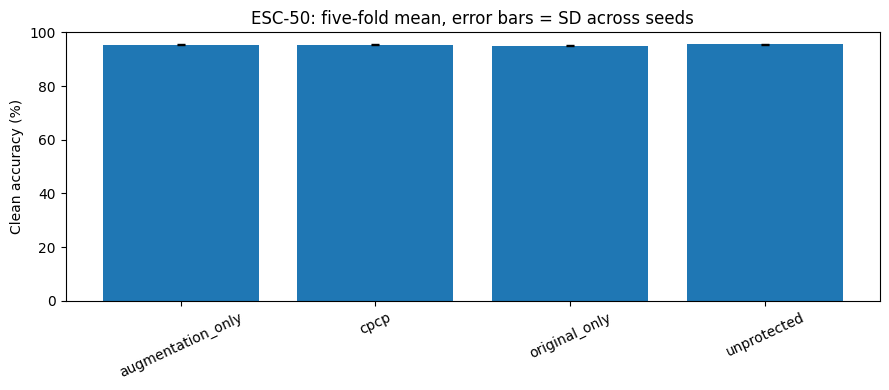

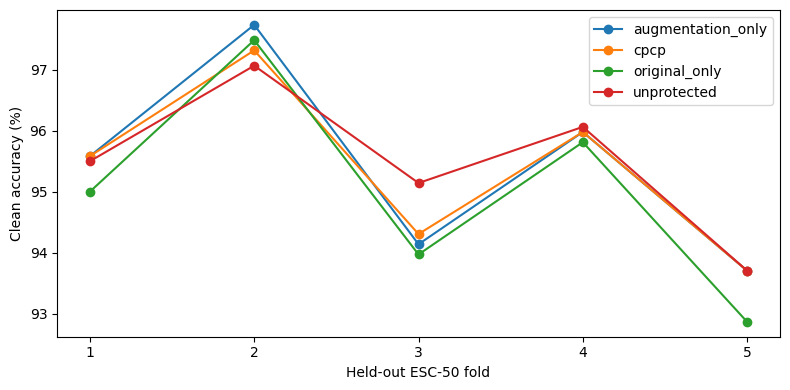

In [14]:
if RUN_ESC_CORE:
    run_core(ESC,'esc50',secondary=RUN_SECONDARY)
    esc_predictions=final_tables('esc50',list(range(1,6)),ESC)
    core_figure('esc50')


## 7 · UrbanSound8K: full ten-fold clean baseline
Load existing extracted audio first (including a nested UrbanSound8K folder). Otherwise use the [authors' 6 GB archive](https://zenodo.org/records/1203745); a download attempt is capped at ten minutes. While new bytes are arriving the notebook automatically resumes, with a limit of twelve attempts per execution. Rerun section 7 if necessary. Alternatively download in your browser and place the complete archive under the printed project folder, or point URBAN_ROOT to the extracted dataset. All eligible clips are tested once across the ten official folds. The frozen AST uses clean embeddings and one fixed-budget linear head per fold; section 9 compares the CNN on exactly those test clips. No Urban filter sweep is required for that comparison.


In [15]:
URBAN=None
if RUN_URBAN_CORE or RUN_TRANSFER or RUN_CNN:
    # Retry a timed-out download only while its resumable archive is growing.
    part=URBAN_ROOT/'UrbanSound8K.tar.gz.part'
    for attempt in range(12):
        before=part.stat().st_size if part.exists() else 0
        urban_dir=prepare_urban(URBAN_ROOT,DOWNLOAD_URBAN)
        if urban_dir is not None or not DOWNLOAD_URBAN or not part.exists() or part.stat().st_size<=before:break
        print('Download made progress; automatically resuming.',flush=True)
    if urban_dir is None:
        print('Urban stages pending: complete the download and rerun sections 7, 9, 12 and 14. ESC sections can continue.')
    else:
        URBAN=urban_manifest(urban_dir)
        if RUN_URBAN_CORE:clean_and_masked(URBAN,'urban8k',['frozen_ast'])


AST feature cache: 100%|██████████| 8580/8580 [00:03<00:00, 2507.41it/s]


8580 rows; 0 newly computed; 3.4 seconds.
urban8k fold 1 frozen_ast saved
urban8k fold 1 frozen_ast saved
urban8k fold 1 frozen_ast saved
urban8k fold 2 frozen_ast saved
urban8k fold 2 frozen_ast saved
urban8k fold 2 frozen_ast saved
urban8k fold 3 frozen_ast saved
urban8k fold 3 frozen_ast saved
urban8k fold 3 frozen_ast saved
urban8k fold 4 frozen_ast saved
urban8k fold 4 frozen_ast saved
urban8k fold 4 frozen_ast saved
urban8k fold 5 frozen_ast saved
urban8k fold 5 frozen_ast saved
urban8k fold 5 frozen_ast saved
urban8k fold 6 frozen_ast saved
urban8k fold 6 frozen_ast saved
urban8k fold 6 frozen_ast saved
urban8k fold 7 frozen_ast saved
urban8k fold 7 frozen_ast saved
urban8k fold 7 frozen_ast saved
urban8k fold 8 frozen_ast saved
urban8k fold 8 frozen_ast saved
urban8k fold 8 frozen_ast saved
urban8k fold 9 frozen_ast saved
urban8k fold 9 frozen_ast saved
urban8k fold 9 frozen_ast saved
urban8k fold 10 frozen_ast saved
urban8k fold 10 frozen_ast saved
urban8k fold 10 frozen_ast s

## 8 · ESC-50 SpecAugment ablation
No masking, frequency only, time only, and both; one fixed sampled view per clip. Every training clip appears twice (the control duplicates the clean clip). All four arms share the same head settings, training size and five test folds. A masked embedding is computed once per clip and mask type, then reused in any fold where that clip is in training. Test predictions use only clean or held-out microphone-filter views. There is no augmentation-count sweep or Urban repetition. The optional frequency MixStyle function is supplied but is not a measured condition in this protocol.


AST feature cache: 100%|██████████| 1991/1991 [00:00<00:00, 9702.72it/s]


1991 rows; 0 newly computed; 0.2 seconds.


AST feature cache: 100%|██████████| 1600/1600 [00:00<00:00, 8654.17it/s]


1600 rows; 0 newly computed; 0.2 seconds.
esc50 fold 1 no_mask saved
esc50 fold 1 no_mask saved
esc50 fold 1 no_mask saved
esc50 fold 1 frequency saved
esc50 fold 1 frequency saved
esc50 fold 1 frequency saved
esc50 fold 1 time saved
esc50 fold 1 time saved
esc50 fold 1 time saved
esc50 fold 1 both saved
esc50 fold 1 both saved
esc50 fold 1 both saved


AST feature cache: 100%|██████████| 1592/1592 [00:00<00:00, 8255.94it/s]


1592 rows; 0 newly computed; 0.2 seconds.
esc50 fold 2 no_mask saved
esc50 fold 2 no_mask saved
esc50 fold 2 no_mask saved
esc50 fold 2 frequency saved
esc50 fold 2 frequency saved
esc50 fold 2 frequency saved
esc50 fold 2 time saved
esc50 fold 2 time saved
esc50 fold 2 time saved
esc50 fold 2 both saved
esc50 fold 2 both saved
esc50 fold 2 both saved


... (5 outputs left out)

AST feature cache: 100%|██████████| 1588/1588 [00:00<00:00, 9133.83it/s]

1588 rows; 0 newly computed; 0.2 seconds.


esc50 fold 5 no_mask saved
esc50 fold 5 no_mask saved
esc50 fold 5 no_mask saved
esc50 fold 5 frequency saved
esc50 fold 5 frequency saved
esc50 fold 5 frequency saved
esc50 fold 5 time saved
esc50 fold 5 time saved
esc50 fold 5 time saved
esc50 fold 5 both saved
esc50 fold 5 both saved
esc50 fold 5 both saved


,method,view,n_seeds,accuracy_pct_mean,accuracy_pct_sd,macro_f1_pct_mean,macro_f1_pct_sd
0,both,clean,3,95.429,0.219,95.309,0.247
5,frequency,clean,3,95.563,0.190,95.446,0.202
10,no_mask,clean,3,95.445,0.203,95.309,0.206
15,time,clean,3,95.512,0.177,95.372,0.180


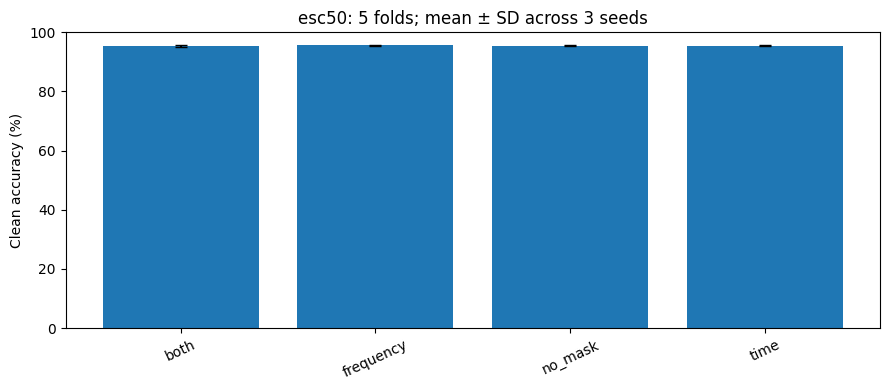

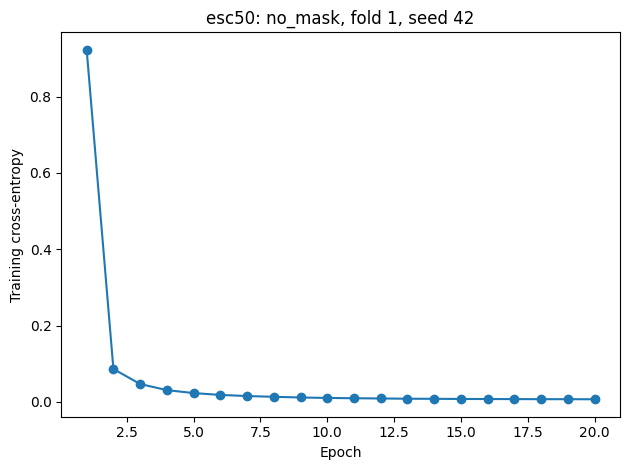

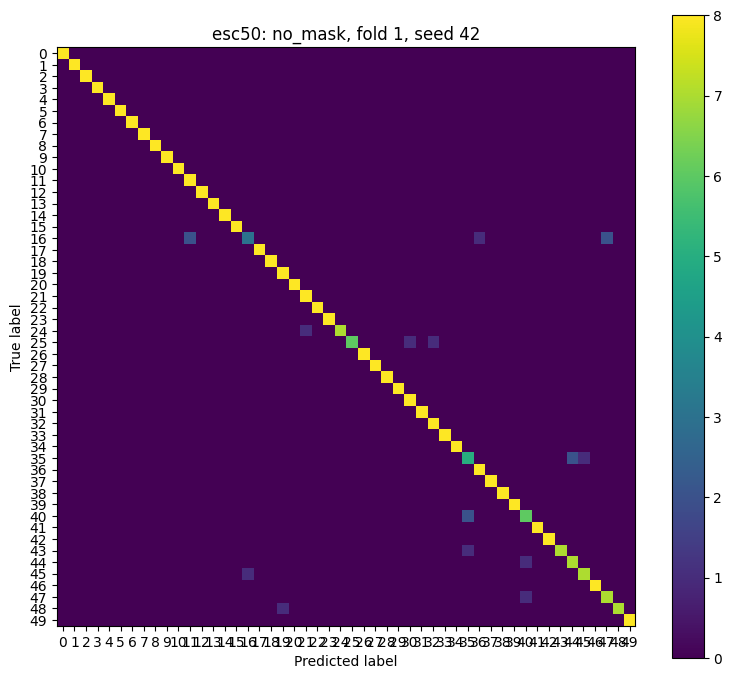

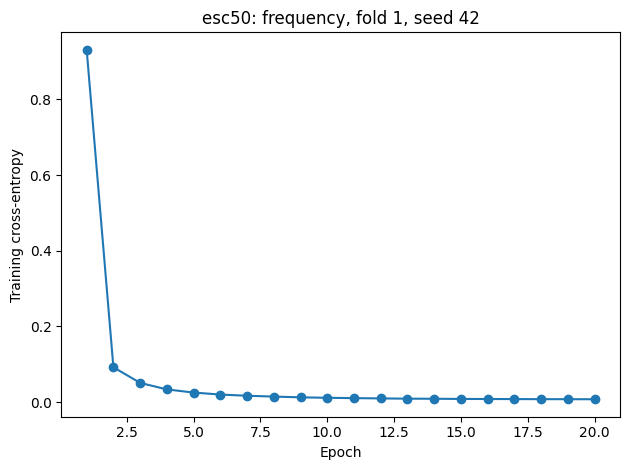

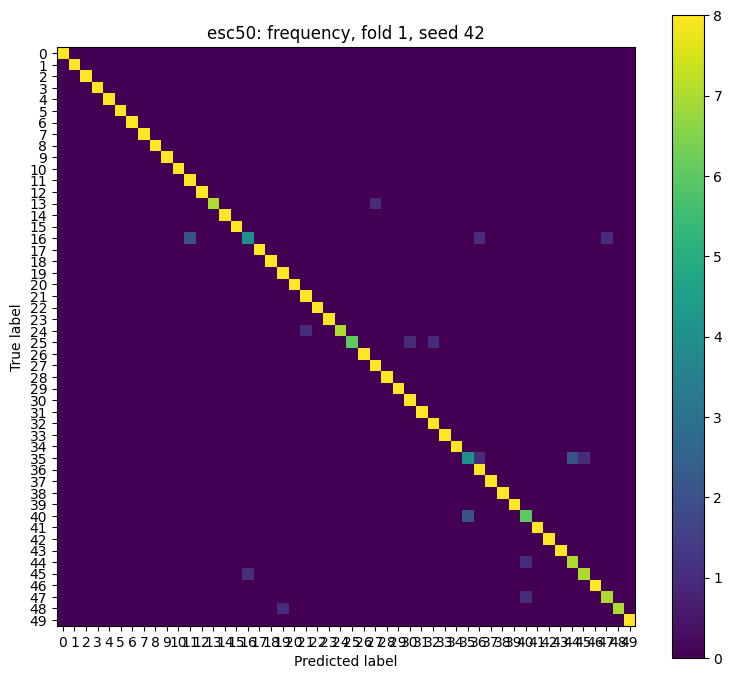

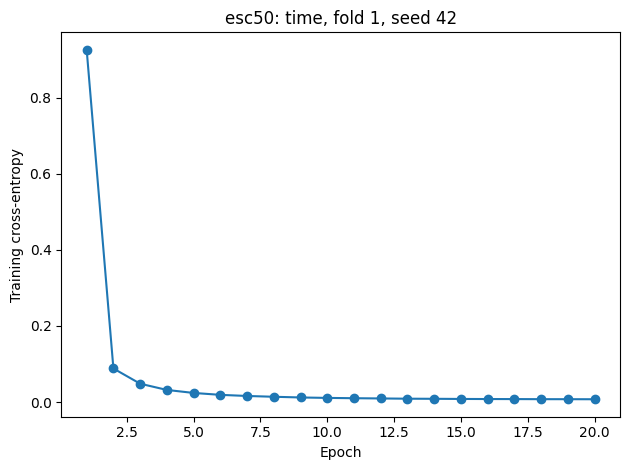

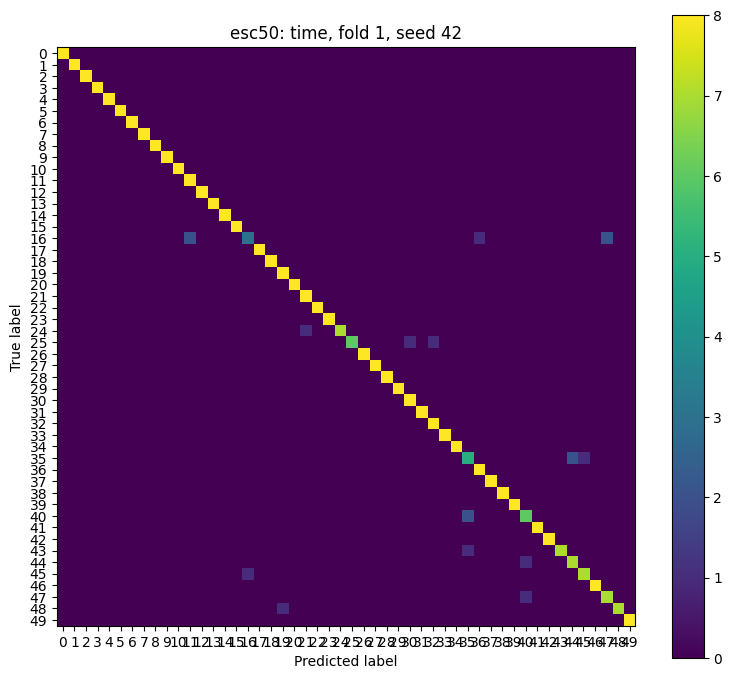

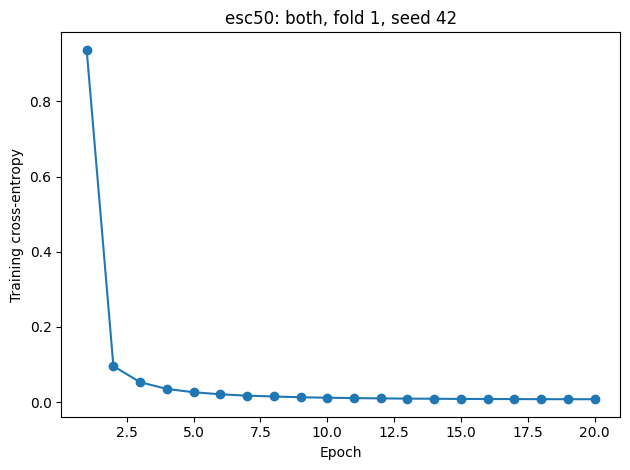

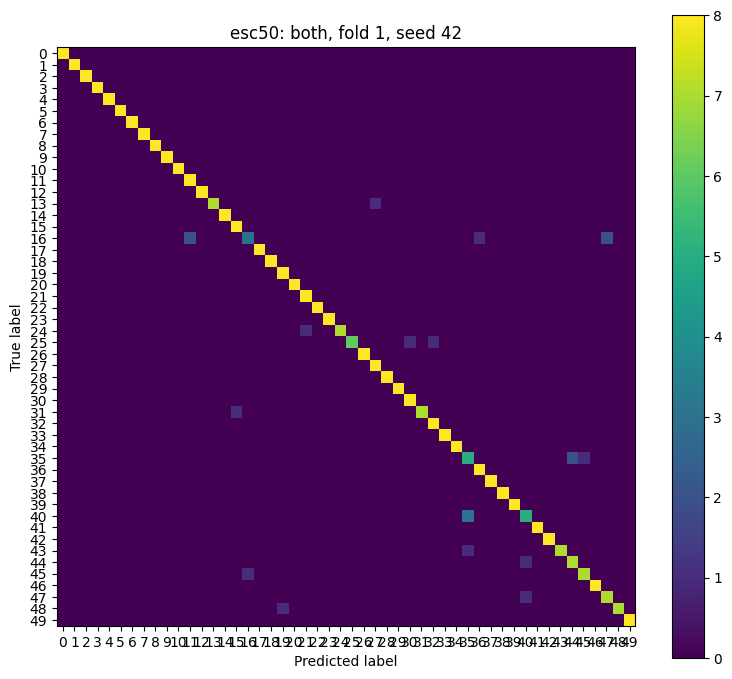

In [16]:
if RUN_AUGMENTATION:
    clean_and_masked(ESC,'esc50',['no_mask','frequency','time','both'])
    export_stages(ESC,'esc50')


## 9 · Compact mel-CNN and budgeted full-backbone AST
The CNN uses all non-test clips, fixed 4×4 average pooling of the mel input, and three epochs by default. The ESC-50 AST updates every backbone layer, but defaults to **four training clips per class per outer fold**, one epoch per initialization and three independent seeds. This caps expensive backward passes while retaining every eligible outer-test clip. Settings are fixed before testing. Describe it as a limited-training-data fine-tuning experiment; it is not a reproduction of a full-data 94% benchmark. Set AST_PER_CLASS=None in section 2 before starting if full training coverage is required. The five-fold three-seed CPCP core in section 6 always uses all eligible data.


In [17]:
if RUN_CNN:
    run_neural_fast(ESC,'esc50','cnn')
    if URBAN is not None:run_neural_fast(URBAN,'urban8k','cnn')
if RUN_FULL_AST:run_neural_fast(ESC,'esc50','ast')


Prepare compact CNN inputs: 100%|██████████| 1991/1991 [00:06<00:00, 316.75it/s]

esc50, fold 1, seed 42, cnn patch 16: 1591 train, 400 test, 3 epoch(s)



Held-out predictions: 100%|██████████| 13/13 [00:00<00:00, 111.36it/s]

esc50, fold 1, seed 123, cnn patch 16: 1591 train, 400 test, 3 epoch(s)



Held-out predictions: 100%|██████████| 13/13 [00:00<00:00, 114.45it/s]

esc50, fold 1, seed 999, cnn patch 16: 1591 train, 400 test, 3 epoch(s)


... (111 outputs left out)

esc50, fold 5, seed 123, ast patch 16: 200 train, 397 test, 1 epoch(s)



Check common spectrogram inputs: 100%|██████████| 597/597 [00:00<00:00, 2638.77it/s]

esc50, fold 5, seed 999, ast patch 16: 200 train, 397 test, 1 epoch(s)



Held-out predictions: 100%|██████████| 199/199 [00:55<00:00,  3.56it/s]


## 10 · Matched patch-size study (ESC-50, outer fold 1)
Use the same sampled training clips, three seeds, test clips, stride 10 and optimizer for patch sizes 8, 16 and 32. Interpolate the pretrained kernel with area scaling and resize the positional grid, retaining the special tokens. Reuse patch 16 from section 9. Report the single-fold table and figure separately from the five-fold main results. Times exclude input-cache preparation; inference timing includes reading cached inputs.


esc50 ast 16 : already complete.


Check common spectrogram inputs: 100%|██████████| 600/600 [00:00<00:00, 3115.58it/s]

esc50, fold 1, seed 42, ast patch 8: 200 train, 400 test, 1 epoch(s)



Check common spectrogram inputs: 100%|██████████| 600/600 [00:00<00:00, 2784.73it/s]

esc50, fold 1, seed 123, ast patch 8: 200 train, 400 test, 1 epoch(s)



Check common spectrogram inputs: 100%|██████████| 600/600 [00:00<00:00, 2930.92it/s]

... (5 outputs left out)


Check common spectrogram inputs: 100%|██████████| 600/600 [00:00<00:00, 3027.92it/s]

esc50, fold 1, seed 999, ast patch 32: 200 train, 400 test, 1 epoch(s)



Held-out predictions: 100%|██████████| 200/200 [00:44<00:00,  4.50it/s]


,method,view,n_seeds,accuracy_pct_mean,accuracy_pct_sd,macro_f1_pct_mean,macro_f1_pct_sd
0,ast_patch16,clean,3,60.757,3.281,58.434,4.069
1,both,clean,3,95.429,0.219,95.309,0.247
6,cnn_patch16,clean,3,24.726,2.360,19.258,2.882
7,frequency,clean,3,95.563,0.190,95.446,0.202
12,no_mask,clean,3,95.445,0.203,95.309,0.206
17,time,clean,3,95.512,0.177,95.372,0.180


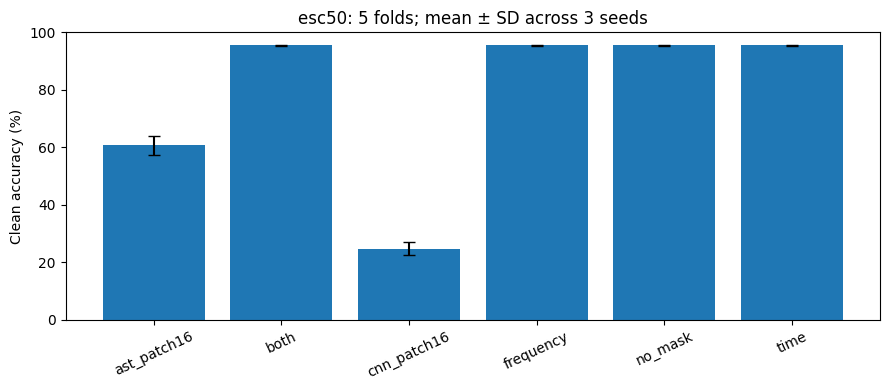

,patch,n_seeds,accuracy_pct_mean,accuracy_pct_sd,ms_per_clip_mean,ms_per_clip_sd,train_seconds_mean,train_seconds_sd
0,8,3,36.750,3.473,160.577,0.725,87.572,0.356
1,16,3,59.750,1.750,145.942,0.383,82.197,3.756
2,32,3,45.083,1.893,111.240,0.190,63.416,0.470


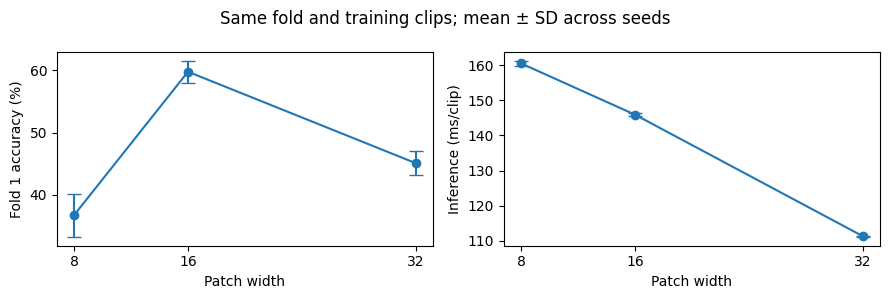

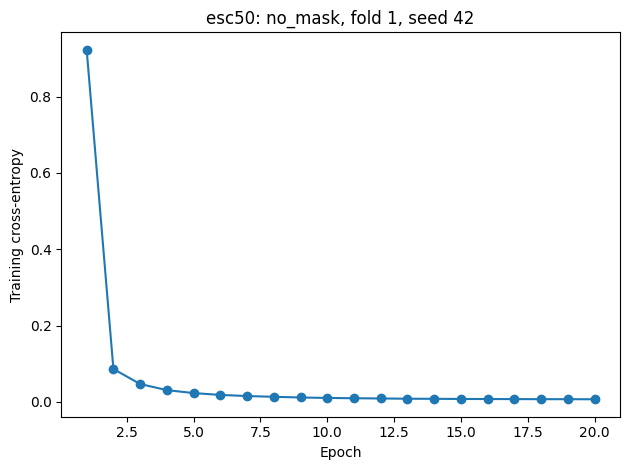

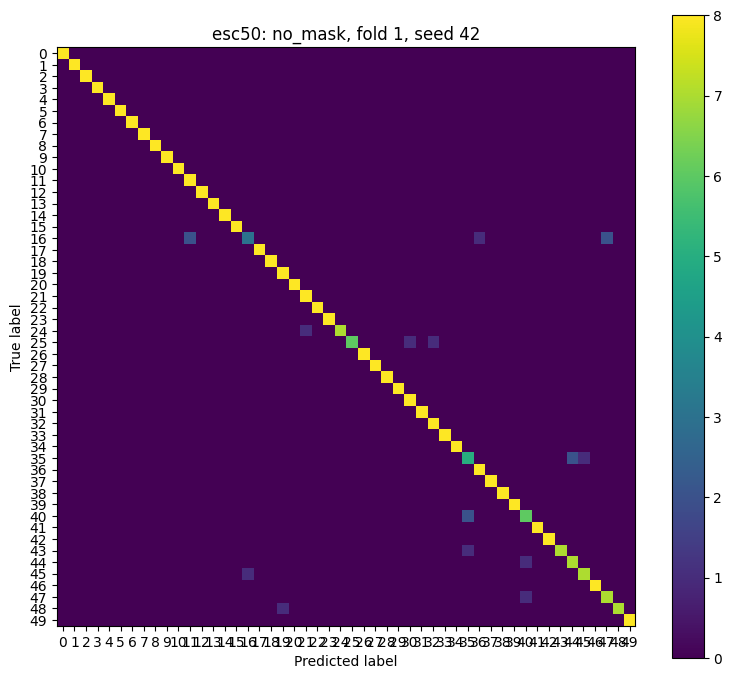

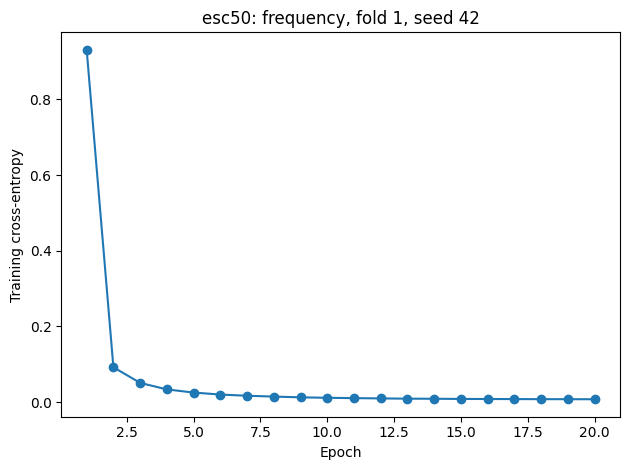

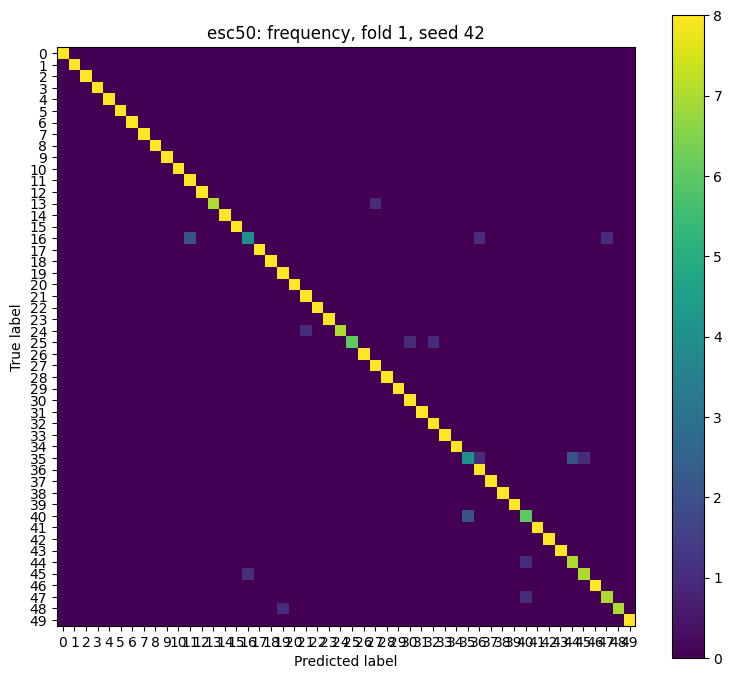

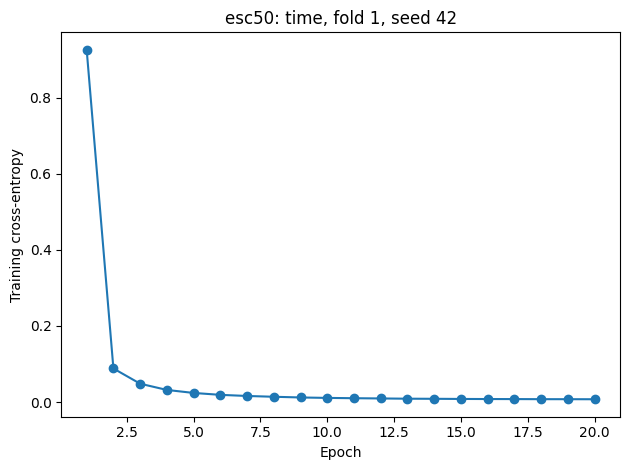

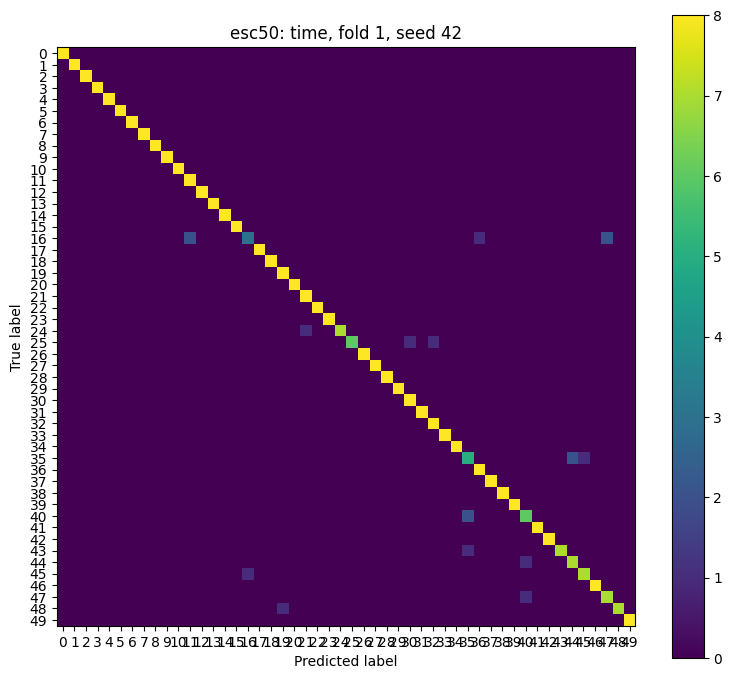

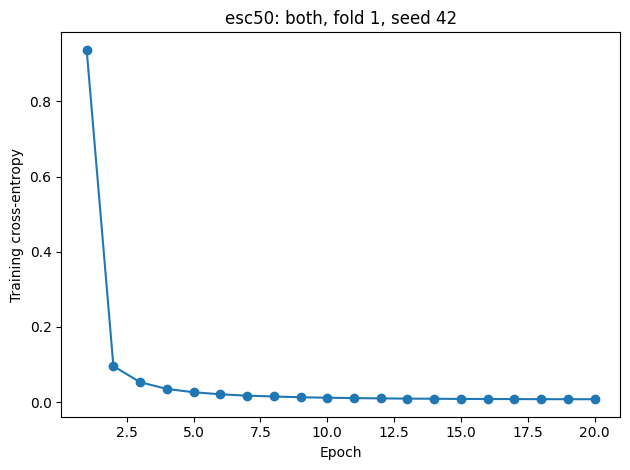

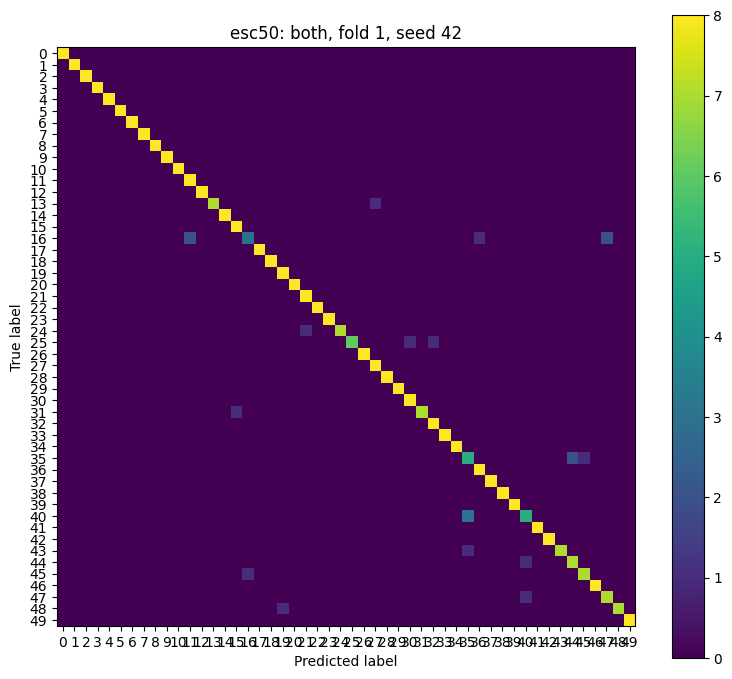

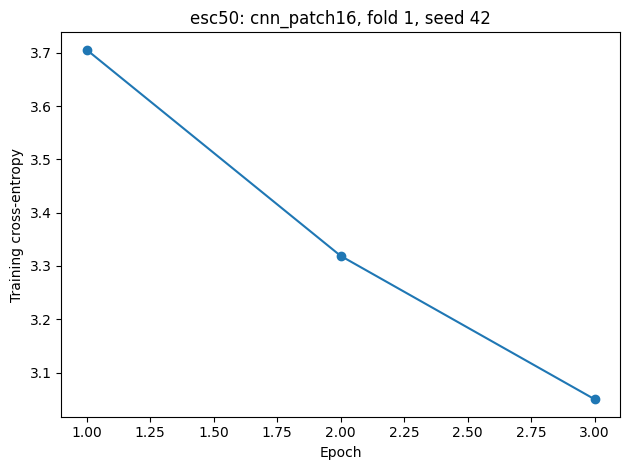

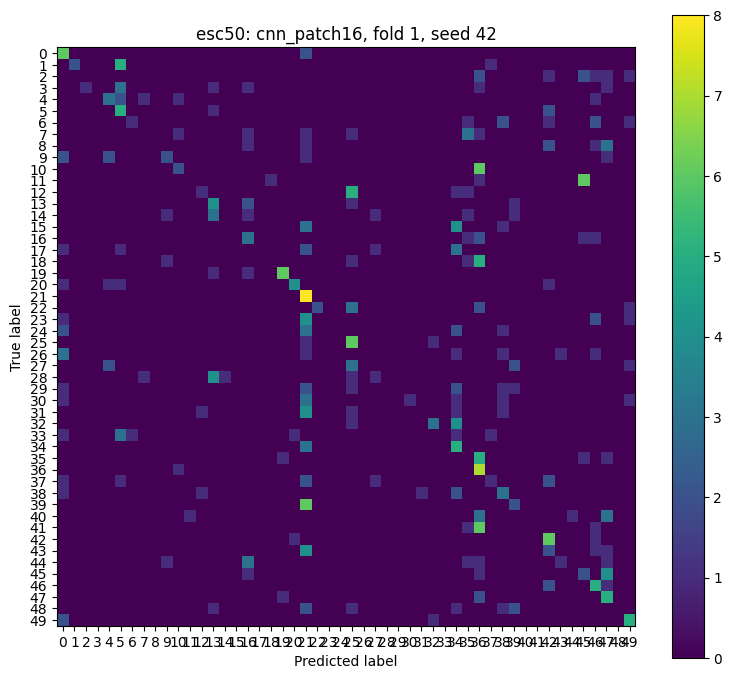

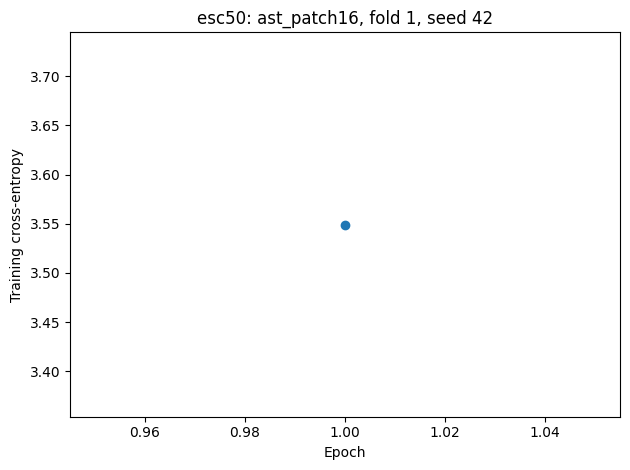

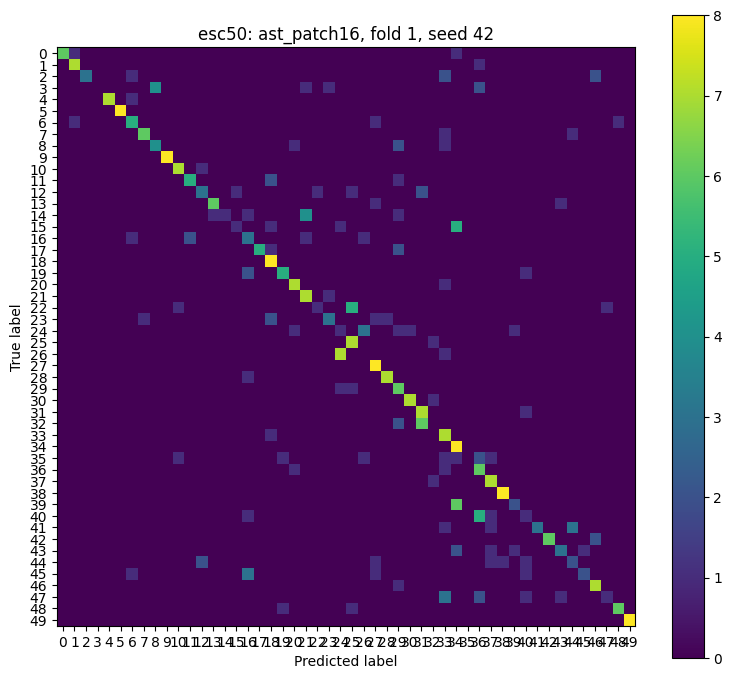

In [18]:
if RUN_PATCH_ABLATION:
    for patch in [16,8,32]:run_neural_fast(ESC,'esc50','ast',patch,folds=[1])
    export_stages(ESC,'esc50')


## 11 Patch attention and perturbation
Use a fixed held-out fold-1 clip after core CV. This inspects the frozen AST used by CPCP and its original-only head. Final-layer CLS/distillation attention is averaged over heads. Mask the top 10% patches and an equal number of random patches, then measure the original predicted-class probability change. Overlapping patches can cover different total areas; this is a diagnostic, not causal proof or a statistically powered attribution study.

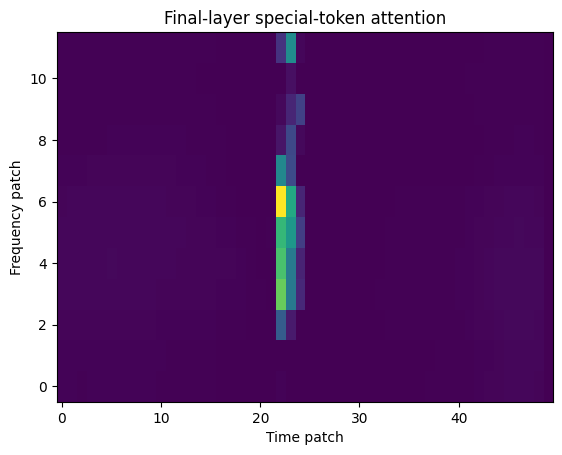

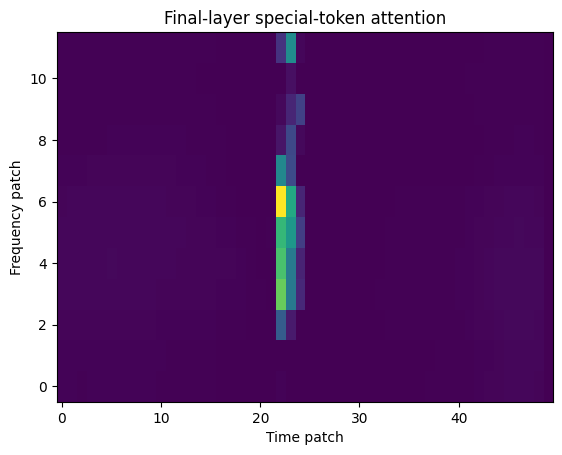

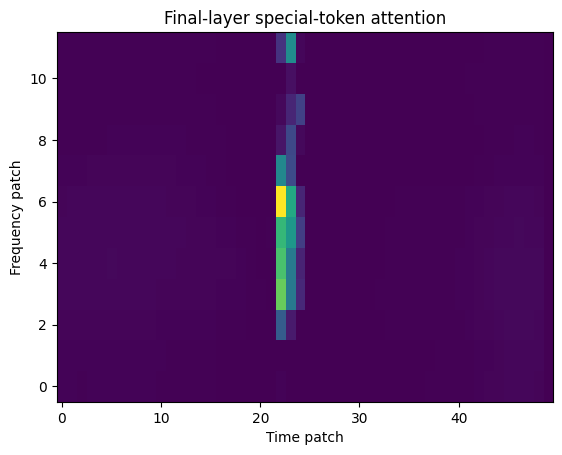

One illustrative clip, three trained heads, same frozen attention and mask locations.


In [19]:
if RUN_ATTENTION:
    row=ESC[ESC.fold.eq(1)].sort_values('filename').iloc[0]
    save_json(FINAL_DIR/'attention_clip.json',dict(filename=row.filename,label=int(row.label),category=row.category))
    cases=[]
    for seed in SEEDS:
        head=FINAL_DIR/f'esc50/fold_1/original_only_{seed}.npz'
        if not head.is_file():raise FileNotFoundError(f'Missing {head}; run section 6.')
        stem=FINAL_DIR/f'attention_seed{seed}'
        attention_check(row,head,stem)
        cases.append(pd.read_csv(stem.with_suffix('.csv')).assign(seed=seed))
    cases=pd.concat(cases,ignore_index=True)
    cases['drop_pp']=100*cases.probability_drop
    atomic_csv(cases,FINAL_DIR/'attention.csv')
    atomic_csv(seed_summary(cases,['region'],['drop_pp']),FINAL_DIR/'attention_summary_percent.csv')
    shutil.copyfile(FINAL_DIR/f'attention_seed{SEEDS[0]}.png',FINAL_DIR/'attention.png')
    print('One illustrative clip, three trained heads, same frozen attention and mask locations.')


## 12 Shared-class cross-dataset transfer
Train on UrbanSound8K dog_bark, siren and car_horn; evaluate ESC-50 dog, siren and car_horn. Remove shared Freesound recording IDs and exact file hashes from the target set. Select settings using UrbanSound8K fold 10 only and refit all source folds. No ESC-50 labels select settings. This is shared-label transfer without target training, not semantic zero-shot recognition of new labels.

AST feature cache: 100%|██████████| 2136/2136 [00:00<00:00, 6400.64it/s]


2136 rows; 0 newly computed; 0.3 seconds.


AST feature cache: 100%|██████████| 216/216 [00:00<00:00, 4852.72it/s]


216 rows; 0 newly computed; 0.0 seconds.


AST feature cache: 100%|██████████| 2352/2352 [00:00<00:00, 19597.72it/s]


2352 rows; 0 newly computed; 0.1 seconds.


AST feature cache: 100%|██████████| 45/45 [00:00<00:00, 3120.45it/s]


45 rows; 0 newly computed; 0.0 seconds.
Shared-class cross-dataset transfer; no ESC-50 tuning. This is not unseen-label zero-shot learning.


,seed,clips,accuracy_pct,macro_f1_pct
0,42,45,82.22,82.06
1,123,45,95.56,93.37
2,999,45,97.78,96.44


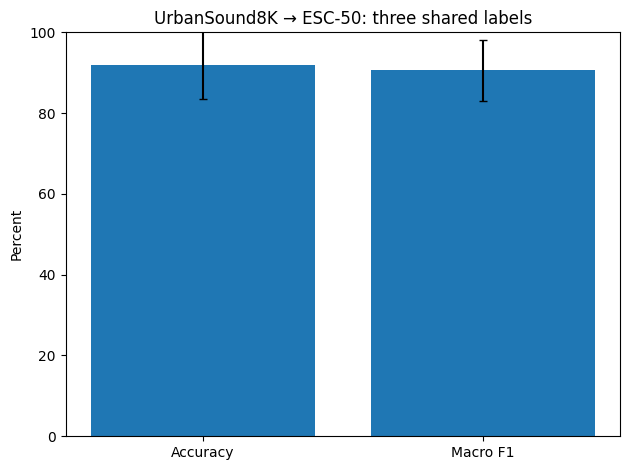

In [20]:
if RUN_TRANSFER:
    if URBAN is not None:
        transfer(URBAN,ESC);transfer_figure()
    else:print('Transfer pending: finish the UrbanSound8K download in section 7.')


## 13 Confidence intervals and reporting
For each seed, average fold metrics first; then report the mean and sample standard deviation over seeds. Bootstrap source recordings inside each fold, retaining all filter views, both methods and seeds together. Intervals describe recording-sampling uncertainty conditional on trained models. No final claim is emitted if core folds/seeds are missing.

In [21]:
if RUN_BOOTSTRAP:
    if 'esc_predictions' not in globals():esc_predictions=final_tables('esc50',list(range(1,6)),ESC)
    ci=paired_bootstrap(esc_predictions,2000);save_json(FINAL_DIR/'esc50/paired_bootstrap.json',ci)
    print('CPCP minus augmentation-only filter macro F1 (pp), with paired 95% interval:',ci)


Bootstrap folds: 100%|██████████| 5/5 [00:00<00:00, 24.81it/s]

CPCP minus augmentation-only filter macro F1 (pp), with paired 95% interval: {'difference_pp': -0.02340571222150256, 'low': -0.16811729965436512, 'high': 0.1312120899107011, 'resamples': 2000, 'contrast': 'CPCP minus augmentation only: average held-out-filter macro F1, percentage points', 'interpretation': 'Recording-sampling uncertainty conditional on fitted runs.'}


## 14 PANNs and final accuracy exports

clean_accuracy       clean_macro_f1       filter_macro_f1  \
                            mean   std           mean   std            mean   
method                                                                        
augmentation_only          95.43  0.18          95.30  0.23           94.93   
cpcp                       95.38  0.10          95.23  0.06           94.90   
original_only              95.03  0.18          94.92  0.14           94.71   
unprotected                95.50  0.08          95.37  0.08           95.07   

                        worst_filter_macro_f1        
                    std                  mean   std  
method                                               
augmentation_only  0.04                 94.35  0.11  
cpcp               0.10                 94.35  0.17  
original_only      0.12                 94.08  0.26  
unprotected        0.09                 94.46  0.08

,method,view,n_seeds,accuracy_pct_mean,accuracy_pct_sd,macro_f1_pct_mean,macro_f1_pct_sd
0,ast_patch16,clean,3,60.757,3.281,58.434,4.069
1,both,clean,3,95.429,0.219,95.309,0.247
6,cnn_patch16,clean,3,24.726,2.360,19.258,2.882
7,frequency,clean,3,95.563,0.190,95.446,0.202
12,no_mask,clean,3,95.445,0.203,95.309,0.206
17,time,clean,3,95.512,0.177,95.372,0.180


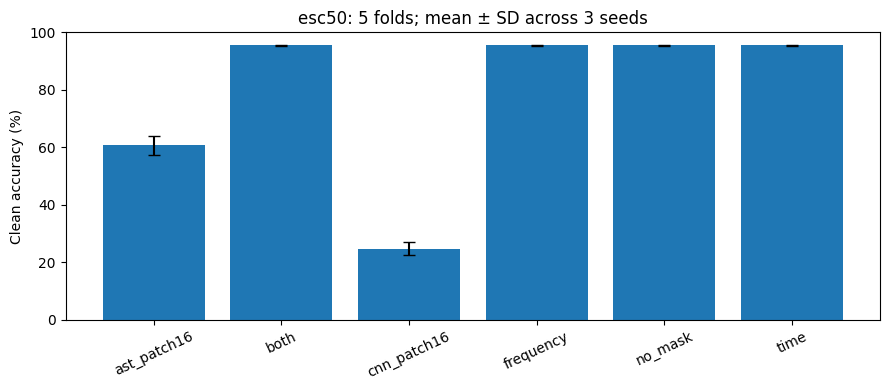

,patch,n_seeds,accuracy_pct_mean,accuracy_pct_sd,ms_per_clip_mean,ms_per_clip_sd,train_seconds_mean,train_seconds_sd
0,8,3,36.750,3.473,160.577,0.725,87.572,0.356
1,16,3,59.750,1.750,145.942,0.383,82.197,3.756
2,32,3,45.083,1.893,111.240,0.190,63.416,0.470


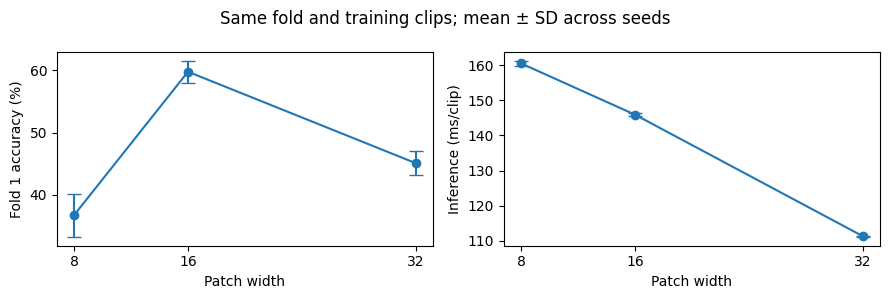

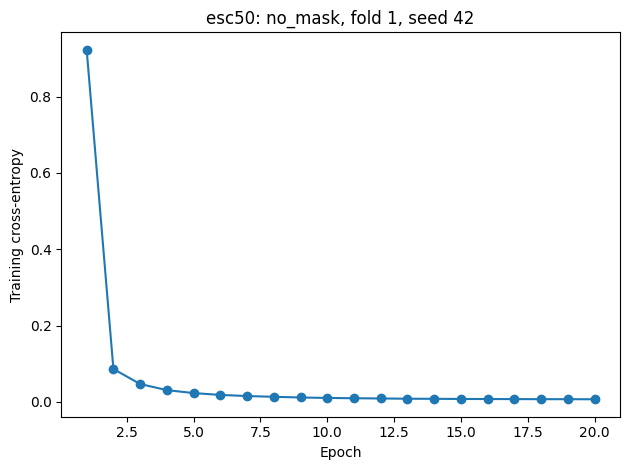

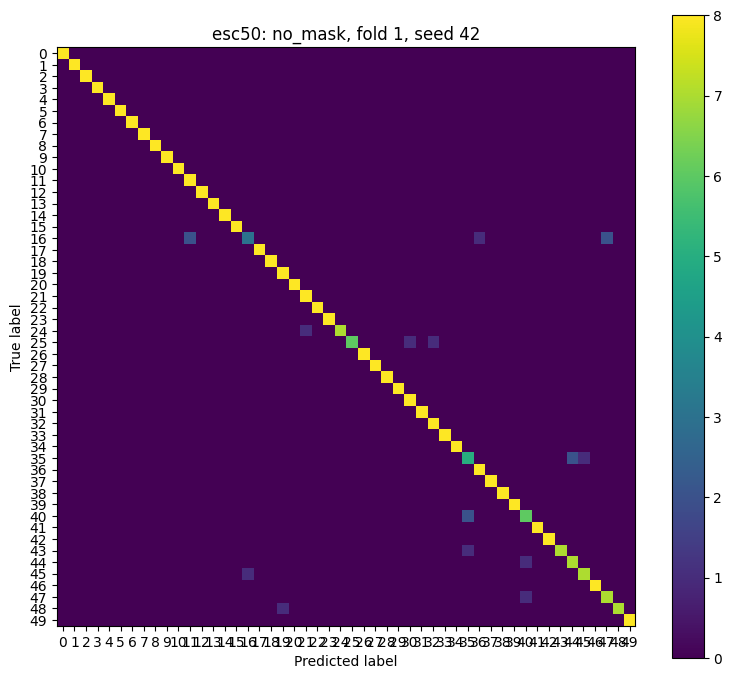

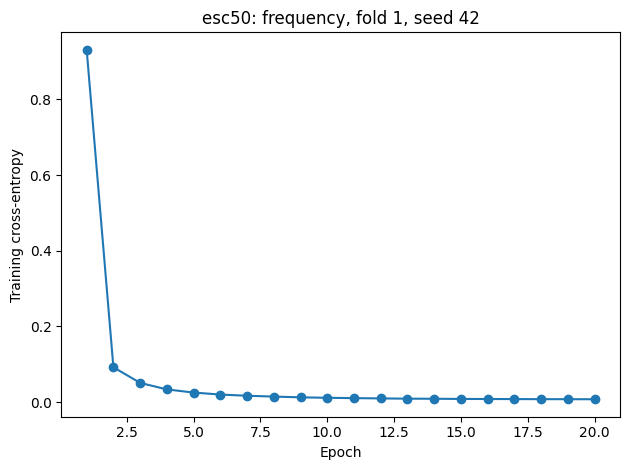

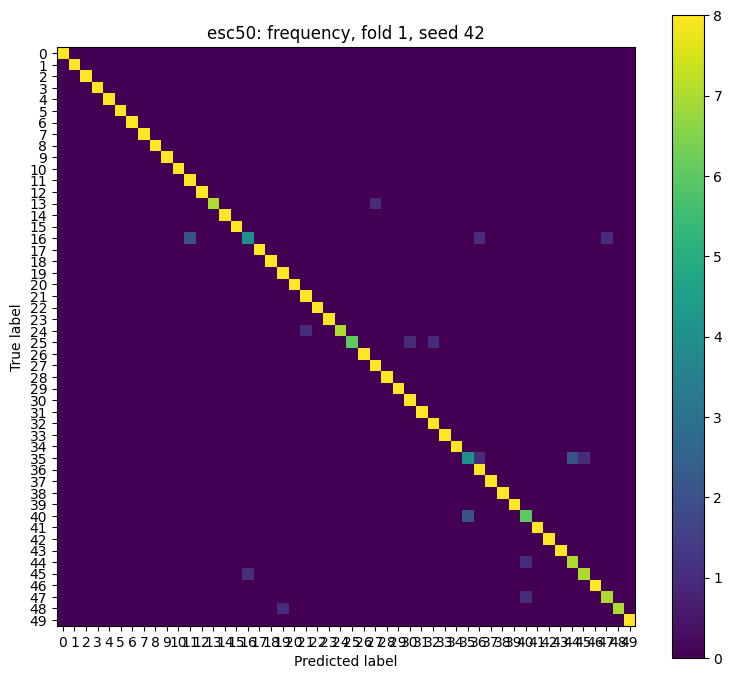

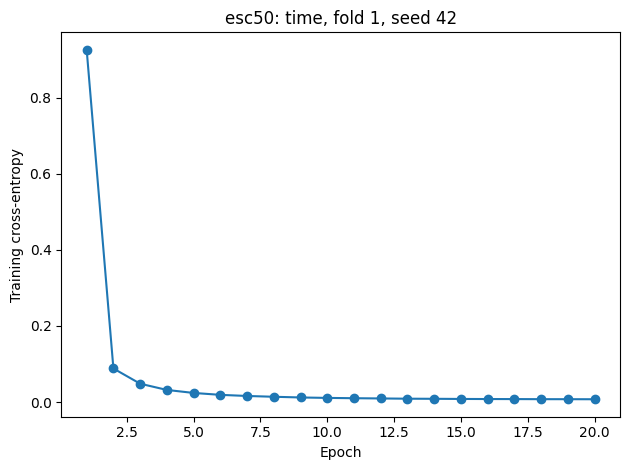

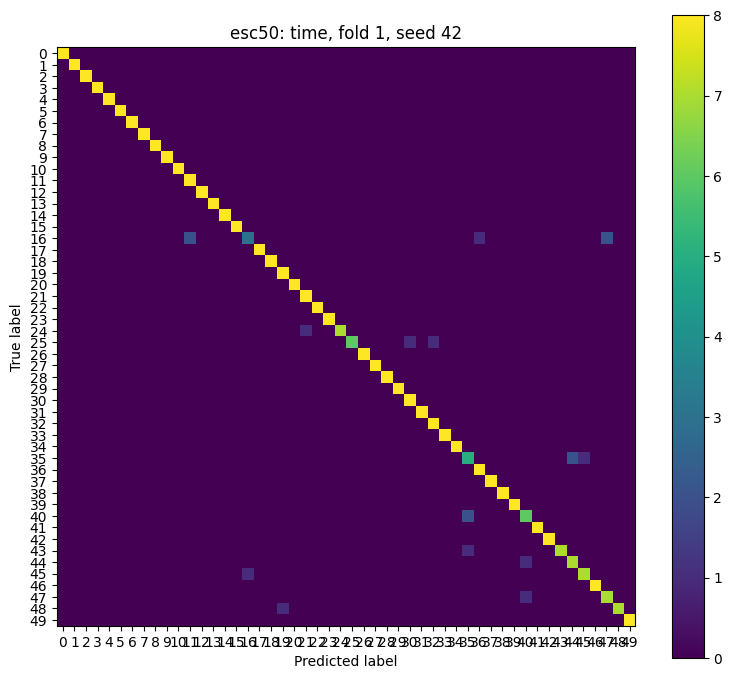

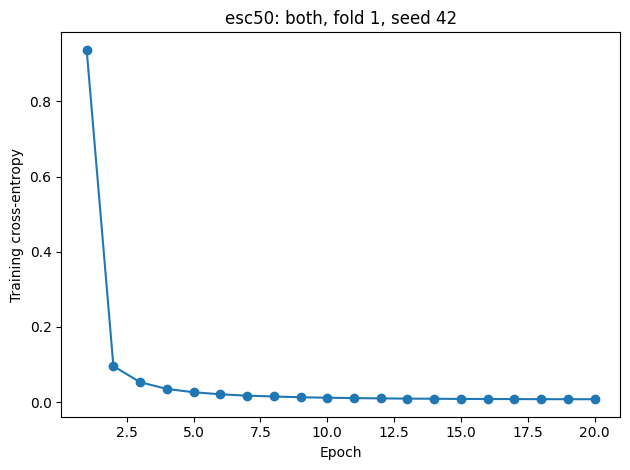

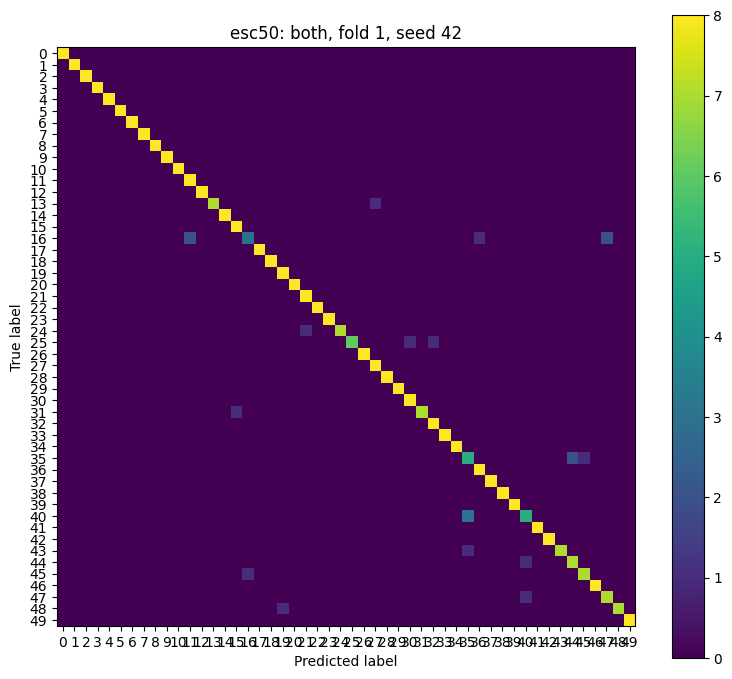

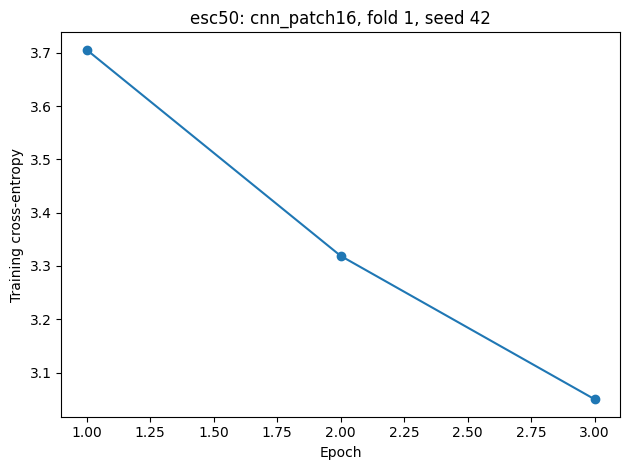

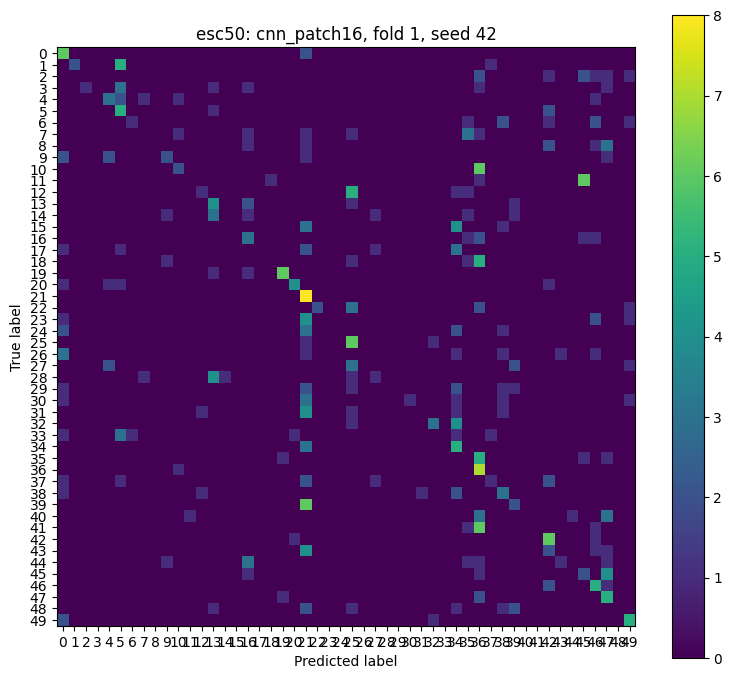

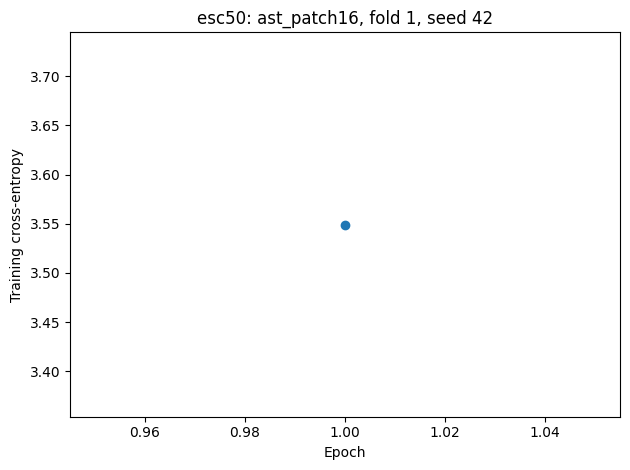

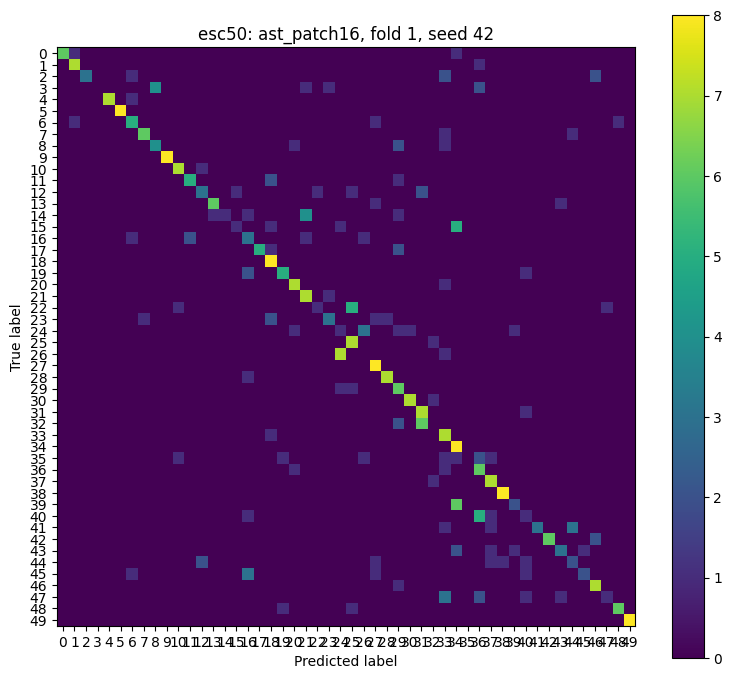

,method,view,n_seeds,accuracy_pct_mean,accuracy_pct_sd,macro_f1_pct_mean,macro_f1_pct_sd
0,cnn_patch16,clean,3,56.157,0.955,55.554,1.179
1,frozen_ast,clean,3,86.244,0.144,86.966,0.106


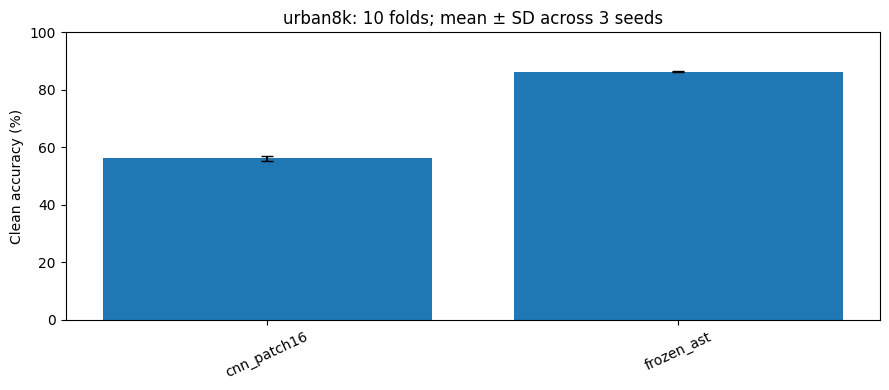

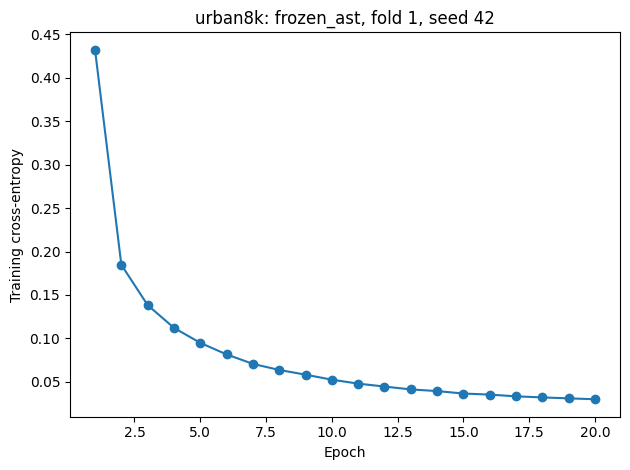

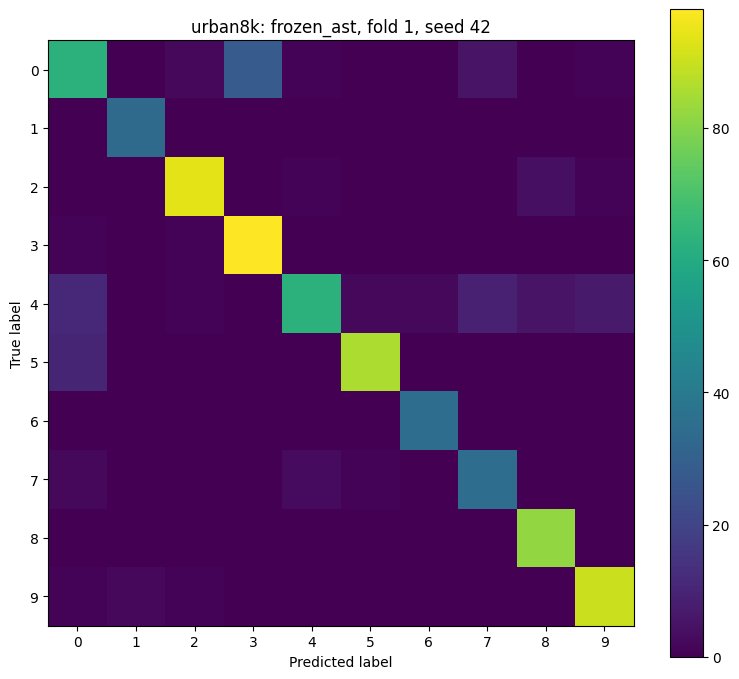

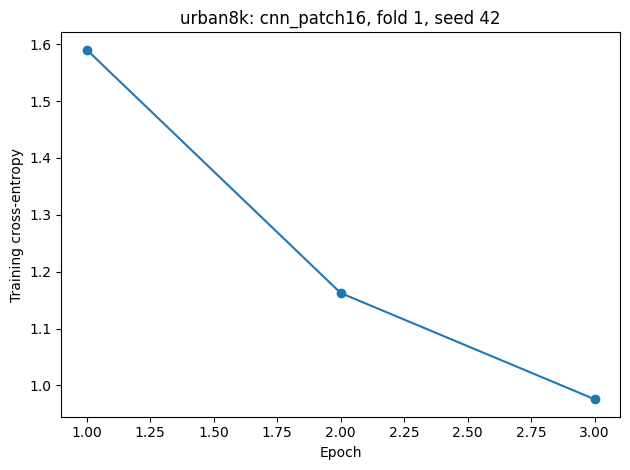

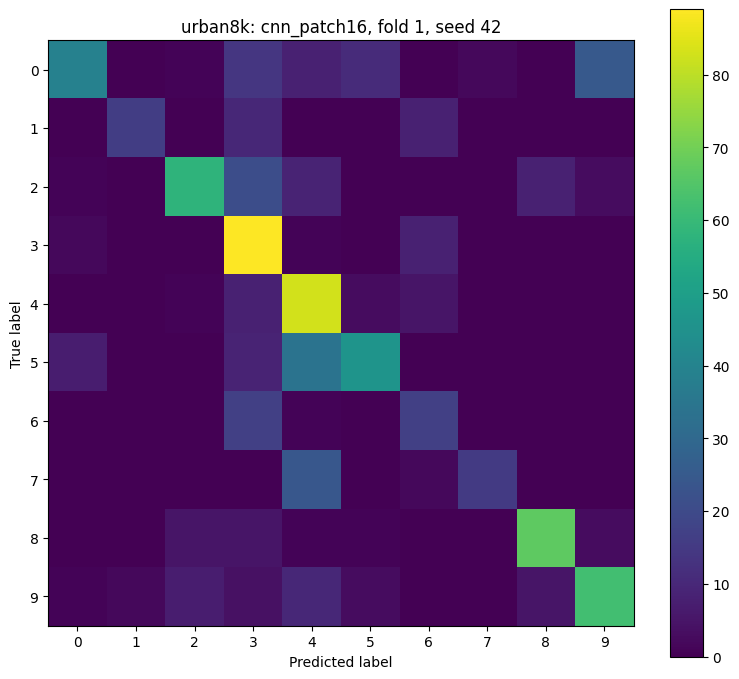

,seed,clips,accuracy_pct,macro_f1_pct
0,42,45,82.22,82.06
1,123,45,95.56,93.37
2,999,45,97.78,96.44


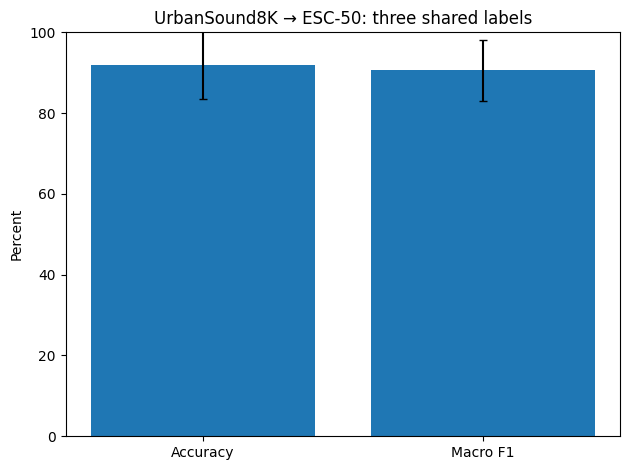

,experiment,completed,expected,status
0,ESC-50 primary folds × seeds,15,15,complete
1,esc50 no_mask,15,15,complete
2,esc50 frequency,15,15,complete
3,esc50 time,15,15,complete
4,esc50 both,15,15,complete
5,esc50 cnn_patch16,15,15,complete
6,esc50 ast_patch16,15,15,complete
7,urban8k frozen_ast,30,30,complete
8,urban8k cnn_patch16,30,30,complete
9,ESC-50 primary coverage and table,2,2,complete


For the report, share: /Users/masih/Downloads/cisc473_audio_three_seeds/final_three_seed/e1c48aa6adf9/report_bundle.zip
ALL REQUIRED RUNS COMPLETE
Report evidence is in: /Users/masih/Downloads/cisc473_audio_three_seeds/final_three_seed/e1c48aa6adf9
Primary: esc50/summary_percent.csv + paired_bootstrap.json. Auxiliary CV: <dataset>/additional_cv_percent.csv.
Single-fold patch comparison: esc50/patch_accuracy_efficiency.csv. Shared-label transfer: transfer_summary_percent.csv.


In [22]:
if RUN_PANNS:
    subprocess.check_call([sys.executable,'-m','pip','install','panns-inference==0.1.1','librosa==0.10.2.post1'])
    run_panns(ESC,'esc50')
if RUN_EXPORT:
    if URBAN is None:raise RuntimeError('Urban data unavailable. Complete sections 7, 9 and 12, then rerun 14. No final export.')
    esc_predictions=final_tables('esc50',list(range(1,6)),ESC)
    export_stages(ESC,'esc50',strict=True)
    if URBAN is not None:export_stages(URBAN,'urban8k',strict=True)
    transfer_figure();report_bundle()
    print('ALL REQUIRED RUNS COMPLETE')
    print('Report evidence is in:',FINAL_DIR)
    print('Primary: esc50/summary_percent.csv + paired_bootstrap.json. Auxiliary CV: <dataset>/additional_cv_percent.csv.')
    print('Single-fold patch comparison: esc50/patch_accuracy_efficiency.csv. Shared-label transfer: transfer_summary_percent.csv.')
